# Домашнее задание 1

**Студент:** Явакаев Роман  
**Группа:** Б05-404

## Требования к выполнению

Сдайте один файл `.ipynb` с кодом, результатами выполнения и обоснованными ответами.
<div style="color: #d00000; font-size: 16px; font-weight: 800; line-height: 1.3; margin-bottom: 24px;">ВНИМАНИЕ!<br>ПОСЛЕ ЗАГРУЗКИ НОУТБУКА В БОТА ЕГО НЕЛЬЗЯ ИЗМЕНЯТЬ ИЛИ ПЕРЕЗАПУСКАТЬ.</div>

Используйте предоставленные разбиения данных. Модели и преобразования обучайте
только на train, гиперпараметры выбирайте по validation. Test используйте
для финальной оценки после фиксации модели и её настроек; изменять решение
по результатам test нельзя. Перед оценкой на test не переобучайте модель
на train + validation.

## Зависимости

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown

SEED = 42
plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.22,
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
pd.set_option("display.max_columns", 12)
pd.set_option("display.width", 130)
pd.set_option("display.precision", 4)
sklearn.set_config(display="text")
print(f"Python {sys.version.split()[0]} | NumPy {np.__version__} | "
      f"pandas {pd.__version__} | scikit-learn {sklearn.__version__} | "
      f"matplotlib {matplotlib.__version__}")

Python 3.13.15 | NumPy 2.5.3 | pandas 3.0.6 | scikit-learn 1.9.1 | matplotlib 3.11.2


## Задача 1. Регуляризация линейной регрессии

Признаки и целевая переменная центрированы. Пусть $X\in\mathbb{R}^{n\times d}$ и

$$\frac{X^\top X}{n}=I_d,\qquad \frac{X^\top y}{n}=c.$$

При $\lambda>0$ заданы функции:

$$L_{\mathrm{OLS}}(w)=\frac{1}{2n}\|y-Xw\|_2^2,$$
$$L_{\mathrm{Ridge}}(w)=\frac{1}{2n}\|y-Xw\|_2^2+\frac{\lambda}{2}\|w\|_2^2,$$
$$L_{\mathrm{Lasso}}(w)=\frac{1}{2n}\|y-Xw\|_2^2+\lambda\|w\|_1.$$

1. Найдите и обоснуйте решения всех трёх задач минимизации.
2. В этом пункте условие $X^\top X/n=I_d$ не предполагается. Для произвольной фиксированной матрицы центрированных признаков докажите, что с ростом $\lambda>0$ евклидова норма оптимального вектора коэффициентов Ridge не возрастает, а обучающая ошибка $\|y-X\hat w_\lambda\|_2^2$ не убывает.
3. Столбец $X_j$ умножили на $a=10$, остальные столбцы не меняли. Как изменить коэффициент, чтобы сохранить предсказания? Как изменятся штрафы для того же предсказания? Сохранится ли оптимальное предсказание OLS? Объясните связь этого преобразования со стандартизацией признаков.
4. Если добавить свободный член $b$, следует ли включать его в штраф? Обоснуйте ответ.

### 1.1

Пусть $R(w)=\frac{1}{2n}\|y-Xw\|_2^2$. Раскроем квадрат и подставим условия $X^\top X/n=I_d$, $X^\top y/n=c$:

$$R(w)=\frac{1}{2n}\left(y^\top y-2w^\top X^\top y+w^\top X^\top X w\right)
=\underbrace{\frac{\|y\|^2}{2n}}_{\text{const}}-w^\top c+\frac12\|w\|_2^2
=\frac12\|w-c\|_2^2+\text{const}.$$

Все три задачи сводятся к приближению w к c, учитывая штраф

**OLS.** $\nabla R(w)=w-c$, гессиан $\nabla^2R=I_d\succ0$ (положительно определена), значит $R$ строго выпукла и стационарная точка - единственный глобальный минимум:

$$\boxed{\hat w_{\mathrm{OLS}}=c.}$$

**Ridge.** $f(w)=\frac12\|w-c\|^2+\frac{\lambda}{2}\|w\|^2+\text{const}$, $\nabla f=w-c+\lambda w$, гессиан $(1+\lambda)I_d\succ0$:

$$\boxed{\hat w_{\mathrm{Ridge}}=\frac{c}{1+\lambda},\qquad \hat w_j=\frac{c_j}{1+\lambda}.}$$

Ноль достигается только в пределе $\lambda\to\infty$, то есть отбросить признаки тяжело

**Lasso.** Задача распадается на $d$ независимых одномерных:

$$f(w)=\sum_{j=1}^{d}\Big[\tfrac12(w_j-c_j)^2+\lambda|w_j|\Big]+\text{const}.$$

Каждое слагаемое строго выпукло, поэтому минимум единствен, а условие оптимальности для выпуклой негладкой функции - $0\in\partial f$. Субдифференциал модуля: $\partial|w_j|=\{\operatorname{sign}w_j\}$ при $w_j\ne0$ и $[-1,1]$ при $w_j=0$. Условие $0\in w_j-c_j+\lambda\,\partial|w_j|$ разбирается по случаям:

* $w_j>0$: $w_j=c_j-\lambda$, что согласовано с $w_j>0$ ровно при $c_j>\lambda$;
* $w_j<0$: $w_j=c_j+\lambda$, согласовано при $c_j<-\lambda$;
* $w_j=0$: нужно $c_j\in\lambda[-1,1]$, то есть $|c_j|\le\lambda$.

Три случая покрывают всю прямую без пересечений, поэтому

$$\boxed{\hat w_{\mathrm{Lasso},j}=\operatorname{sign}(c_j)\max(|c_j|-\lambda,\,0)=S_\lambda(c_j)}$$

**Геометрическая аналогия.** Линии уровня $R$ - сферы с центром $c$. Решение задачи со штрафом - точка касания сферы и линии уровня штрафа. У шара $\ell_2$ граница гладкая, касание в типичном случае происходит во внутренней точке грани, где все координаты ненулевые. У шара $\ell_1$ есть угловые точки, лежащие **на осях координат**, и касание гладкой сферы с выпуклым многогранником с положительной вероятностью происходит именно в вершине - то есть с нулевыми координатами.

### 1.2

Обозначим $R(w)=\frac{1}{2n}\|y-Xw\|_2^2$, $P(w)=\frac12\|w\|_2^2$, $f_\lambda=R+\lambda P$ и $\hat w_\lambda=\arg\min f_\lambda$. При $\lambda>0$ гессиан $f_\lambda$ равен $X^\top X/n+\lambda I\succ0$, значит минимум существует и единствен при любой фиксированной $X$ (в том числе вырожденной).

**Доказательство обмена (двухточечный аргумент).** Пусть $0<\lambda_1<\lambda_2$, $w_1=\hat w_{\lambda_1}$, $w_2=\hat w_{\lambda_2}$. Из оптимальности каждой точки в своей задаче:

$$R(w_1)+\lambda_1P(w_1)\le R(w_2)+\lambda_1P(w_2),$$
$$R(w_2)+\lambda_2P(w_2)\le R(w_1)+\lambda_2P(w_1).$$

Сложим неравенства, слагаемые $R$ сократятся:

$$\lambda_1P(w_1)+\lambda_2P(w_2)\le\lambda_1P(w_2)+\lambda_2P(w_1)
\;\Longleftrightarrow\;(\lambda_2-\lambda_1)\big(P(w_2)-P(w_1)\big)\le0 .$$

Так как $\lambda_2>\lambda_1$, получаем $P(w_2)\le P(w_1)$, то есть $\|\hat w_{\lambda_2}\|_2\le\|\hat w_{\lambda_1}\|_2$ - норма не возрастает. Подставив это в первое неравенство:

$$R(w_1)-R(w_2)\le\lambda_1\big(P(w_2)-P(w_1)\big)\le0\;\Longrightarrow\;R(w_1)\le R(w_2),$$

то есть обучающая ошибка не убывает. $\blacksquare$

### 1.3

**Преобразование.** $\tilde X=XA$, где $A=\operatorname{diag}(1,\dots,\underbrace{a}_{j},\dots,1)$, $a=10$.

**Как сохранить предсказание.** $\tilde X\tilde w=XA\tilde w=Xw$ выполняется тогда и только тогда, когда $A\tilde w=w$, то есть

$$\boxed{\tilde w_j=\frac{w_j}{a}=\frac{w_j}{10},\qquad \tilde w_k=w_k\ (k\ne j).}$$

Содержательно: признак стал в 10 раз «крупнее», значит на единицу его изменения ответ должен меняться в 10 раз слабее.

**Штрафы за то же самое предсказание.**

$$\|\tilde w\|_2^2=\|w\|_2^2-w_j^2\Big(1-\frac1{a^2}\Big)=\|w\|_2^2-0{,}99\,w_j^2,\qquad
\|\tilde w\|_1=\|w\|_1-|w_j|\Big(1-\frac1a\Big)=\|w\|_1-0{,}9\,|w_j|.$$

Вклад $j$-й координаты падает в $a^2=100$ раз для Ridge и в $a=10$ раз для Lasso. Одно и то же предсказание стало стоить дешевле, значит признак $j$ стал эффективно почти нештрафуемым, а все остальные - относительно дорогими. Оптимум задачи со штрафом поэтому меняется.

**OLS сохраняется.** Прогноз OLS - ортогональная проекция $y$ на линейную оболочку столбцов: $\hat y=P_{\operatorname{span}X}\,y$. Матрица $A$ обратима, поэтому $\operatorname{span}(\tilde X)=\operatorname{span}(X)$ - подпространство то же, проекция та же, оптимальное предсказание не меняется; меняются только координаты в новом базисе, по формуле $\tilde w=A^{-1}w$ (однозначно, если $X$ полного ранга; если нет, множество решений переходит в себя под действием $A^{-1}$). Эксперимент 3.3 это подтверждает: $\max|\Delta\hat y|\approx6\cdot10^{-12}$ для OLS против $20{,}0$ для Ridge без стандартизации.

**Связь со стандартизацией.** Стандартизация - это тот же самый множитель с выбором $a_j=1/s_j$ (плюс центрирование). Отсюда два вывода:

1. Для OLS стандартизация ничего не меняет - это просто смена базиса в пространстве параметров, а функция подгонки зависит только от подпространства.
2. Для штрафуемых моделей она необходима, потому что единственное число $\lambda$ штрафует все координаты с одинаковым весом, а это осмысленно, только если координаты соизмеримы.

### 1.4

**Ответ: свободный член штрафовать не следует.**

**Формальное основание.** Пусть модель $\hat y_i=x_i^\top w+b$ и $b$ не штрафуется. Тогда

$$\frac{\partial}{\partial b}\frac1{2n}\sum_i(y_i-x_i^\top w-b)^2=-\frac1n\sum_i(y_i-x_i^\top w-b)=0
\;\Longrightarrow\;\hat b=\bar y-\bar x^\top\hat w .$$

Из этого равенства сразу следуют все содержательные аргументы.

**1. Инвариатность относительно сдвига ответа.** Заменим $y\mapsto y+c$. Тогда $\hat b\mapsto\hat b+c$, а $\hat w$ не меняется - модель не зависит от произвольного выбора начала отсчёта. Если же $b$ штрафуется, то штраф $\lambda b^2/2$ «притягивает» прогноз к значению $y=0$, которое не имеет никакого объективного смысла: решение начинает зависеть от того, в каких единицах и от какой точки измерен ответ. Это нарушение симметрии задачи, а не регуляризация.

**2. Предел $\lambda\to\infty$.** Со свободным членом вне штрафа $\hat w\to0$ и $\hat b\to\bar y$, то есть модель вырождается ровно в `DummyRegressor(strategy="mean")` - разумную нулевую модель, с которой мы и сравниваемся в 3.2. Если штрафовать $b$, предел будет $\hat y\equiv0$, что **хуже тривиальной модели** и обычно хуже вообще всего. Регуляризация должна стягивать модель к простому разумному пределу, а не к произвольной точке.

**3. Свободный член не добавляет сложности.** Регуляризация борется с переобучением, то есть с чувствительностью модели к шуму в данных через коэффициенты при признаках. У $b$ нет признака, на который он умножается: он не может «подстроиться под конкретный объект», его вклад одинаков для всех объектов. Сжатие $b$ не уменьшает дисперсию предсказаний сколько-нибудь существенно, зато вносит прямое систематическое смещение $\lambda$-порядка во все прогнозы сразу.

**4. Инвариантность относительно центрирования признаков.** Сдвиг $x\mapsto x+u$ при нештрафуемом $b$ компенсируется заменой $b\mapsto b-u^\top w$ без изменения $w$. При штрафуемом $b$ эта компенсация становится платной, и результат зависит от того, центрировали ли мы признаки, опять зависимость от произвольного соглашения.

## Задача 2. Метрики классификации и порог решения

Положительный класс — $y=1$. Для объектов заданы оценки вероятности $p(x)\in[0,1]$.
Правило классификации: $\hat y=1$, если $p(x)\geq t$, иначе $\hat y=0$.

1. На фиксированной конечной выборке, содержащей оба класса, исследуйте монотонность recall, precision и accuracy как функций порога $t$. Утверждения обоснуйте доказательствами или контрпримерами. Precision рассматривайте при наличии положительных предсказаний.
2. Стоимость верного решения равна 0, ложноположительного — $c_{FP}>0$, ложноотрицательного — $c_{FN}>0$. В этом пункте считайте $p(x)=P(y=1\mid x)$ истинной условной вероятностью. Выведите порог, минимизирующий ожидаемую стоимость ошибки. Обязан ли он минимизировать фактическую стоимость ошибок на любой конечной выборке? Докажите утверждение или приведите контрпример.
3. Пусть $p(x)=\sigma(w^\top x+b)$, где $\sigma(z)=1/(1+e^{-z})$. Какой порог на $z=w^\top x+b$ соответствует порогу $0<t<1$? При каких условиях порог из пункта 2 применим к прогнозам обученной модели?

### 2.1

Зафиксируем конечную выборку из $n$ объектов с метками $y_i$ и оценками $p_i$, пусть $n_1>0$ и $n_0>0$ - числа объектов классов 1 и 0. Множество положительных предсказаний $P(t)=\{i:p_i\ge t\}$. Ключевое свойство:

$$t\le t'\;\Longrightarrow\;P(t')\subseteq P(t),$$

то есть при росте порога множество положительных предсказаний **только сужается** (вложенное семейство). Отсюда немедленно: $\mathrm{TP}(t)=|P(t)\cap\{y=1\}|$ и $\mathrm{FP}(t)=|P(t)\cap\{y=0\}|$ не возрастают, а $\mathrm{FN}=n_1-\mathrm{TP}$ и $\mathrm{TN}=n_0-\mathrm{FP}$ не убывают.

---

**Recall — монотонно не возрастает.**

$$\mathrm{recall}(t)=\frac{\mathrm{TP}(t)}{n_1}.$$

Знаменатель $n_1$ **не зависит от $t$**, числитель не возрастает (вложенность), значит recall не возрастает.

---

**Precision — не монотонно ни в одну сторону.**

$$\mathrm{precision}(t)=\frac{\mathrm{TP}(t)}{\mathrm{TP}(t)+\mathrm{FP}(t)}.$$

*Контрпример.* Четыре объекта с оценками и метками $(0{,}9;\,1),\ (0{,}8;\,0),\ (0{,}7;\,1),\ (0{,}1;\,0)$ — оба класса присутствуют. Тогда

| $t$ | $P(t)$ | precision |
|---|---|---|
| $(0{,}8;\,0{,}9]$ | $\{0{,}9\}$ | $1/1=1$ |
| $(0{,}7;\,0{,}8]$ | $\{0{,}9;\,0{,}8\}$ | $1/2=0{,}5$ |
| $(0{,}1;\,0{,}7]$ | $\{0{,}9;\,0{,}8;\,0{,}7\}$ | $2/3\approx0{,}67$ |

При росте $t$ precision идёт $0{,}67\to0{,}5\to1$: сначала убывает, потом возрастает. Монотонности нет ни в каком направлении. $\blacksquare$

*Механизм.* Precision — это **текущее среднее меток по префиксу** отсортированного списка. Среднее при удлинении префикса растёт, если добавленный элемент выше текущего среднего, и падает иначе; оба случая возможны. Поэтому precision колеблется, хотя при хорошем ранжировании общая тенденция — рост с порогом (положительные скапливаются в начале списка). В п. 4.4 это видно на реальных данных: на validation у precision **15 участков убывания** из 500 шагов сетки порогов при общем росте с $0{,}707$ до $1{,}000$.

---

**Accuracy — не монотонно.**

$$\mathrm{accuracy}(t)=\frac{\mathrm{TP}(t)+\mathrm{TN}(t)}{n}
=\frac{n_1\,\mathrm{recall}(t)+n_0\,(1-\mathrm{FPR}(t))}{n}.$$

Первое слагаемое не возрастает, второе не убывает — разнонаправленная сумма, и в общем случае монотонности нет.

*Контрпример.* Два объекта: $(p=0{,}9;\,y=1)$ и $(p=0{,}1;\,y=0)$.

| $t$ | предсказания | accuracy |
|---|---|---|
| $t\le0{,}1$ | $1,1$ | $1/2$ |
| $0{,}1<t\le0{,}9$ | $1,0$ | $1$ |
| $t>0{,}9$ | $0,0$ | $1/2$ |

Accuracy сначала растёт, потом падает. $\blacksquare$

*Механизм.* При понижении порога через очередной объект accuracy меняется на $+1/n$, если у объекта метка 1, и на $-1/n$, если метка 0. То есть accuracy — **случайное блуждание с шагами $\pm1/n$** вдоль ранжированного списка, и знак шага равен метке. Монотонность была бы только при вырожденном ранжировании (все метки одного знака, что исключено условием «оба класса присутствуют»).

---

**Объединяющий вывод.** Из трёх метрик монотонна ровно та, у которой **знаменатель не зависит от порога**. У recall это $n_1$ — константа выборки; у precision знаменатель $|P(t)|$ сам сжимается вместе с числителем, у accuracy складываются два встречных вклада. Поэтому по одному recall нельзя судить о качестве (он максимизируется тривиальным $t=0$), и порог всегда выбирается как компромисс — см. 2.2 и 4.4.

### 2.2

**Вывод порога.** Пусть в точке $x$ известна истинная $p=p(x)=P(y=1\mid x)$. Условные ожидаемые издержки двух решений:

$$\mathbb{E}[\text{cost}\mid x,\hat y=1]=c_{FP}\,P(y=0\mid x)=c_{FP}(1-p),\qquad
\mathbb{E}[\text{cost}\mid x,\hat y=0]=c_{FN}\,p .$$

Предсказываем 1 тогда и только тогда, когда это не дороже:

$$c_{FP}(1-p)\le c_{FN}\,p\iff p\,(c_{FP}+c_{FN})\ge c_{FP}\iff
\boxed{p\ge t^*=\frac{c_{FP}}{c_{FP}+c_{FN}}}$$

Эквивалентная форма через шансы, которая пригодится в 2.3:

$$\frac{p}{1-p}\ge\frac{c_{FP}}{c_{FN}}.$$

**Проверка на крайних случаях.** $c_{FP}=c_{FN}\Rightarrow t^*=1/2$ — обычное правило большинства. $c_{FN}\gg c_{FP}$ (пропуск злокачественной опухоли много дороже ложной тревоги) $\Rightarrow t^*\to0$: предсказываем 1 почти всегда. $c_{FP}\gg c_{FN}\Rightarrow t^*\to1$. Всё согласовано с интуицией.

**Почему это минимум именно ожидаемой стоимости.** Полные ожидаемые издержки произвольного решающего правила $\delta$ по формуле полного математического ожидания:

$$\mathbb{E}[\text{cost}(\delta)]=\mathbb{E}_x\Big[\mathbb{E}\big[\text{cost}\mid x,\delta(x)\big]\Big].$$

Правило выше минимизирует **внутреннее** условное ожидание поточечно, в каждой точке $x$ отдельно, выбирая меньшее из двух чисел. Значит для любого другого правила (в том числе рандомизированного — его условная стоимость есть выпуклая комбинация тех же двух чисел и не меньше минимума) подынтегральное выражение не меньше в каждой точке, следовательно не меньше и интеграл. Это байесовское решающее правило. $\blacksquare$

---

**Обязан ли он минимизировать фактическую стоимость на конечной выборке? Нет.**

*Контрпример.* Выборка из одного объекта, $c_{FP}=c_{FN}=1$, истинная $p(x)=0{,}6$. Тогда $t^*=0{,}5$ и правило предсказывает $\hat y=1$. Но реализация метки случайна: с вероятностью $0{,}4$ окажется $y=0$, и фактические издержки составят $1$, тогда как предсказание $\hat y=0$ дало бы $0$. То есть на этой конкретной реализации **любой порог $t>0{,}6$ строго лучше** оптимального. $\blacksquare$

*Почему так, а не иначе.* $t^*$ минимизирует усреднение по распределению меток. Фактическая стоимость на фиксированной выборке — другая функция порога: кусочно-постоянная, со скачками в точках $p_i$, и её точка минимума сама является случайной величиной. Совпадение гарантируется лишь в пределе: по закону больших чисел эмпирическая стоимость сходится к ожидаемой (равномерно по конечному множеству существенно различных порогов), поэтому $t^*$ асимптотически оптимален, а при конечном $n$ — оптимален «в среднем по выборкам», но не на каждой.

*Практическое следствие.* Порог, подобранный по конечной validation, сам переобучается: это ещё один гиперпараметр со своей дисперсией. В п. 4.4 на validation всего $n_1=43$ объекта класса 1, так что один объект стоит $1/43\approx0{,}023$ recall — подбирать порог до третьего знака бессмысленно.

### 2.3

**Порог на $z$.** Сигмоида $\sigma(z)=1/(1+e^{-z})$ строго возрастает и биективно отображает $\mathbb{R}$ на $(0,1)$, поэтому неравенство можно переносить под неё без изменения знака:

$$p(x)\ge t\iff\sigma(z)\ge t\iff z\ge\sigma^{-1}(t),\qquad
\boxed{z^*=\sigma^{-1}(t)=\ln\frac{t}{1-t}=\operatorname{logit}t.}$$

Частные значения: $t=0{,}5\Rightarrow z^*=0$ (обычная граница $w^\top x+b=0$); $t=0{,}2\Rightarrow z^*=-1{,}386$; $t=0{,}8\Rightarrow z^*=+1{,}386$ (симметрия $\operatorname{logit}(1-t)=-\operatorname{logit}t$).

**Геометрия.** Правило $w^\top x+b\ge z^*$ переписывается как $w^\top x+(b-z^*)\ge0$: меняется **только свободный член**. Разделяющая гиперплоскость переносится параллельно самой себе вдоль нормали $w$, её направление не меняется. Отсюда важное следствие, которое проверяется в 4.4: порог не трогает ни оценки $p(x)$, ни порядок объектов по $p$ — он лишь выбирает точку разреза уже построенного ранжирования.

**Связка с 2.2.** Подставив $t^*=c_{FP}/(c_{FP}+c_{FN})$:

$$z^*=\ln\frac{t^*}{1-t^*}=\ln\frac{c_{FP}}{c_{FN}}.$$

В пространстве логитов оптимальное правило — сдвиг границы на логарифм отношения стоимостей. Это и есть причина, по которой логистическая регрессия удобна: издержки входят аддитивно в ту же шкалу, в которой модель линейна.

---

**Когда порог из п. 2.2 применим к прогнозам обученной модели.** Вывод в 2.2 опирался на равенство $p(x)=P(y=1\mid x)$. Для обученной модели это уже не тождество, а требование, и оно распадается на несколько условий.

1. **Калиброванность.** $\hat p(x)$ должна быть оценкой вероятности, а не просто монотонным рангом. Если модель ранжирует правильно, но систематически завышает/занижает уверенность (отступ SVM, доля голосов kNN, частота в листе глубокого дерева), то $t^*$ попадёт не в ту рабочую точку. Проверяется калибровочной кривой на отложенных данных, чинится Platt scaling или изотонической регрессией.
2. **Правильная спецификация модели.** Логистическая регрессия состоятельно оценивает $p$, только если истинный лог-шанс приблизительно линеен по $x$. В задаче 4 используются 2 признака из 30, и в полосе перекрытия (4.1) линейность лог-шанса — грубое приближение, так что $\hat p$ там смещена.
3. **Регуляризация смещает вероятности.** Малое $C$ сжимает $\|w\|$, то есть делает сигмоиду более пологой и прогнозы систематически **менее уверенными** (ближе к $0{,}5$). При сильном штрафе $t^*$ применять нельзя без перекалибровки.
4. **Совпадение априорных долей классов.** Если при обучении использовались `class_weight`, передискретизация или просто другая пропорция классов, то $\hat p$ отвечает другому априорному распределению, и лог-шанс нужно сдвинуть на $\ln\frac{\pi'_1/\pi'_0}{\pi_1/\pi_0}$ (поправка на prior shift). Без этого порог систематически смещён.
5. **Стоимости постоянны и исчерпывают потери**, распределение признаков на применении совпадает с обучающим, а данные для проверки порога не участвовали в обучении.

Если хотя бы одно условие нарушено, честный способ — не подставлять $t^*$, а **минимизировать эмпирическую стоимость по порогу на validation**, помня оговорку из 2.2: такая оценка шумная, и её доверительный интервал нужно учитывать.

## Задача 3. Регрессия

Используйте набор данных `Diabetes`: 442 наблюдения, 10 признаков и численный
показатель прогрессирования диабета через год. Признаки: `age` — возраст,
`sex` — пол, `bmi` — индекс массы тела, `bp` — среднее артериальное давление,
`s1`–`s6` — лабораторные показатели.

Рассматриваются OLS — линейная регрессия методом наименьших квадратов,
Ridge — линейная регрессия с L2-регуляризацией и Lasso — с L1-регуляризацией.
В качестве базовой модели используется `DummyRegressor`, предсказывающий
среднее значение целевой переменной на обучающей выборке.

Данные загружаются с `scaled=False`. Разбиение train / validation / test —
приблизительно 60 / 20 / 20%. Финальная оценка на test выполняется в пункте 3.5.

[Описание данных](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_diabetes.html).

In [2]:
from IPython.display import Markdown as reg_Markdown
from sklearn.datasets import load_diabetes as reg_load_diabetes
from sklearn.dummy import DummyRegressor as reg_DummyRegressor
from sklearn.linear_model import (
    LinearRegression as reg_LinearRegression,
    Ridge as reg_Ridge,
    Lasso as reg_Lasso,
)
from sklearn.metrics import mean_squared_error as reg_mean_squared_error
from sklearn.model_selection import train_test_split as reg_train_test_split
from sklearn.pipeline import Pipeline as reg_Pipeline
from sklearn.preprocessing import StandardScaler as reg_StandardScaler

reg_dataset = reg_load_diabetes(as_frame=True, scaled=False)
reg_X_train, reg_X_holdout, reg_y_train, reg_y_holdout = reg_train_test_split(
    reg_dataset.data, reg_dataset.target, test_size=0.4, random_state=SEED
)
reg_X_valid, reg_X_test, reg_y_valid, reg_y_test = reg_train_test_split(
    reg_X_holdout, reg_y_holdout, test_size=0.5, random_state=SEED
)
del reg_dataset, reg_X_holdout, reg_y_holdout

def reg_rmse(y_true, y_pred):
    return float(np.sqrt(reg_mean_squared_error(y_true, y_pred)))

print(f"Train: {len(reg_y_train)}; validation: {len(reg_y_valid)}; "
      f"test: {len(reg_y_test)} наблюдений.")

Train: 265; validation: 88; test: 89 наблюдений.


### 3.1

На train проверьте пропуски, повторяющиеся строки и диапазоны признаков.
Постройте диаграмму `bmi`–`target` и вычислите корреляции между признаками.

1. Сравните численные масштабы признаков.
2. Как интерпретировать числовые значения `sex`? Достаточно ли одного столбца для представления этого признака в линейной модели со свободным членом?
3. Найдите тесно коррелирующую пару признаков. Как такая связь влияет на интерпретацию коэффициентов линейной модели?
4. Можно ли сделать вывод о причинном влиянии `bmi` на ответ? Обоснуйте ответ.

Пропусков в признаках: 0 | пропусков в target: 0
Полных дубликатов строк: 0
Объектов в train: 265

Диапазоны признаков на train:


,min,max,mean,std,размах
age,19.000,79.000,48.694,12.980,60.00
sex,1.000,2.000,1.460,0.499,1.00
bmi,18.600,41.300,26.611,4.450,22.70
bp,62.000,133.000,94.792,13.973,71.00
s1,110.000,301.000,189.966,35.052,191.00
s2,41.600,242.400,115.532,30.615,200.80
s3,22.000,99.000,50.062,13.147,77.00
s4,2.000,9.090,4.073,1.296,7.09
s5,3.496,6.107,4.657,0.525,2.61
s6,58.000,124.000,91.725,11.359,66.00


Значения sex: [np.float64(1.0), np.float64(2.0)] | доли: {1.0: 0.54, 2.0: 0.46}


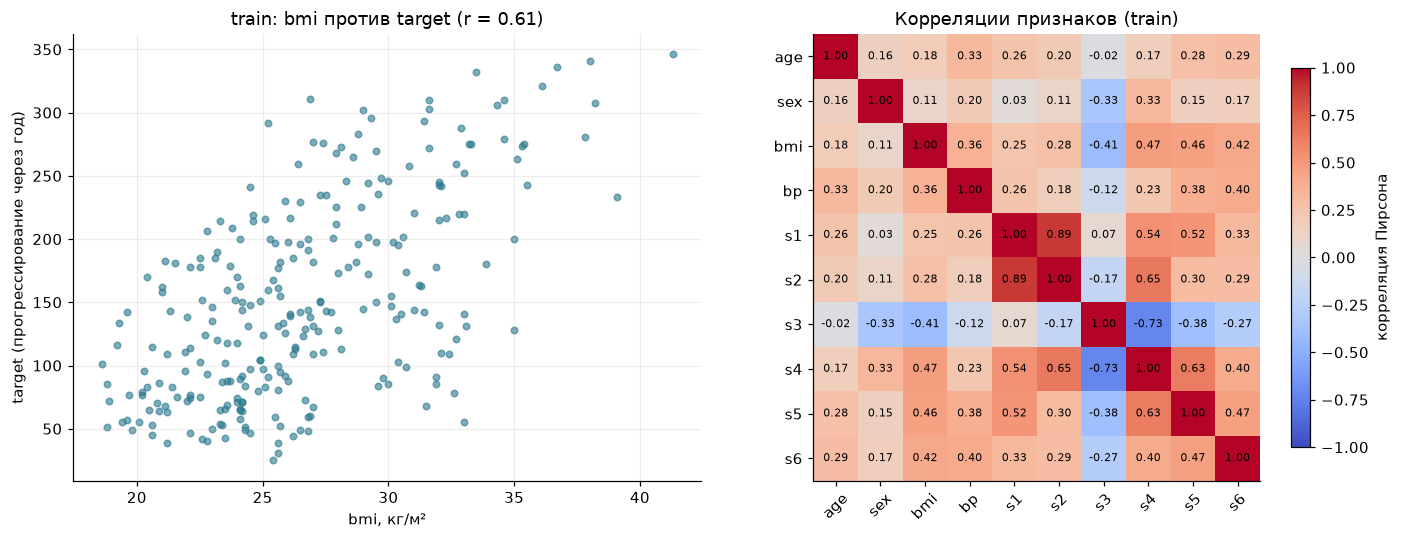

Пять самых связанных пар признаков:


,признак 1,признак 2,корреляция
0,s2,s1,0.890
1,s4,s3,-0.726
2,s2,s4,0.646
3,s4,s5,0.627
4,s4,s1,0.543


Корреляция признаков с target:


,corr с target
bmi,0.607
s5,0.516
bp,0.434
s4,0.419
s6,0.378
age,0.190
s1,0.179
s2,0.155
sex,0.042
s3,-0.398


In [3]:
# ---- проверки качества данных (только train) ----
print("Пропусков в признаках:", int(reg_X_train.isna().sum().sum()),
      "| пропусков в target:", int(reg_y_train.isna().sum()))
print("Полных дубликатов строк:", int(reg_X_train.duplicated().sum()))
print("Объектов в train:", len(reg_X_train))

reg_ranges = reg_X_train.describe().T[["min", "max", "mean", "std"]]
reg_ranges["размах"] = reg_ranges["max"] - reg_ranges["min"]
print("\nДиапазоны признаков на train:")
display(reg_ranges.round(3))

print("Значения sex:", sorted(reg_X_train["sex"].unique()),
      "| доли:", reg_X_train["sex"].value_counts(normalize=True).round(3).to_dict())

# ---- bmi против target и матрица корреляций ----
reg_corr = reg_X_train.corr()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(reg_X_train["bmi"], reg_y_train, s=18, alpha=0.6, color="#2a788e")
axes[0].set(xlabel="bmi, кг/м²", ylabel="target (прогрессирование через год)",
            title=f"train: bmi против target (r = {np.corrcoef(reg_X_train['bmi'], reg_y_train)[0, 1]:.2f})")

im = axes[1].imshow(reg_corr.values, cmap="coolwarm", vmin=-1, vmax=1)
axes[1].set_xticks(range(len(reg_corr)))
axes[1].set_xticklabels(reg_corr.columns, rotation=45)
axes[1].set_yticks(range(len(reg_corr)))
axes[1].set_yticklabels(reg_corr.columns)
axes[1].grid(False)
for i in range(len(reg_corr)):
    for j in range(len(reg_corr)):
        axes[1].text(j, i, f"{reg_corr.values[i, j]:.2f}", ha="center", va="center", fontsize=7)
axes[1].set_title("Корреляции признаков (train)")
fig.colorbar(im, ax=axes[1], shrink=0.85, label="корреляция Пирсона")
fig.tight_layout()
plt.show()

# ---- самые сильные пары и связь с ответом ----
reg_abs_corr = reg_corr.abs().to_numpy(copy=True)
np.fill_diagonal(reg_abs_corr, 0.0)
reg_pairs = (pd.DataFrame(reg_abs_corr, index=reg_corr.index, columns=reg_corr.columns)
             .stack().sort_values(ascending=False))
reg_seen, reg_top = set(), []
for (a, b), _ in reg_pairs.items():
    if (b, a) in reg_seen:
        continue
    reg_seen.add((a, b))
    reg_top.append({"признак 1": a, "признак 2": b, "корреляция": reg_corr.loc[a, b]})
    if len(reg_top) == 5:
        break
print("Пять самых связанных пар признаков:")
display(pd.DataFrame(reg_top).round(3))

print("Корреляция признаков с target:")
display(reg_X_train.corrwith(reg_y_train).sort_values(ascending=False).round(3).to_frame("corr с target"))

#### Ответ

**Качество данных.** Пропусков нет, полных дубликатов строк нет, в train 265 наблюдений на 10 признаков (отношение $\approx26{:}1$ — запас для линейной модели комфортный, переобучения OLS ожидать не стоит).

**1. Масштабы признаков несопоставимы.** Размахи отличаются на два порядка: `sex` — 1, `s5` — 2,61, `s4` — 7,09, `bmi` — 22,7, тогда как `s1` — 191 и `s2` — 200,8. Стандартные отклонения: от 0,499 (`sex`) до 35,05 (`s1`), разброс примерно в 70 раз. Сами по себе эти числа — артефакт единиц измерения (годы, кг/м², мм рт. ст., мг/дл), а не свойство задачи. Для OLS это безразлично (1.3), но для Ridge/Lasso с единым `alpha` и для любых метрических методов — критично: именно это проверяется в 3.3.

**2. `sex` принимает значения $\{1,2\}$** — это **код категории, а не количество**: «2» не означает «вдвое больше, чем 1», среднее 1,46 интерпретируется только как доля группы (46% объектов со значением 2). Одного столбца в линейной модели со свободным членом **достаточно и необходимо**: бинарный признак несёт ровно одну степень свободы, и его коэффициент читается как разность средних между группами при прочих равных. Две индикаторные колонки вместе со свободным членом дали бы линейную зависимость ($\mathbb{1}_{\text{муж}}+\mathbb{1}_{\text{жен}}=\mathbb{1}$, dummy trap), матрица $X^\top X$ стала бы вырожденной, и коэффициенты перестали бы быть определены однозначно. Аффинное перекодирование $1/2\to0/1$ меняет только свободный член, а не наклон.

**3. Тесно коррелирующая пара: `s1`–`s2`, $r=0{,}890$** (далее `s3`–`s4` с $r=-0{,}726$, `s2`–`s4` с $0{,}646$, `s4`–`s5` с $0{,}627$). Это **почти мультиколлинеарность**: у $X^\top X$ есть направление с малым собственным значением, вдоль которого вектор коэффициентов можно двигать далеко почти без изменения качества подгонки. Следствия для интерпретации:
* дисперсия оценок отдельных коэффициентов велика, знаки неустойчивы;
* нельзя читать «коэффициент при `s1`» как «вклад `s1`» — идентифицируема только комбинация.

Это видно прямо в 3.4: при `alpha=0,1` коэффициенты $w_{s_1}=-30{,}5$ и $w_{s_2}=+16{,}1$ велики и противоположны (они почти гасят друг друга), а при `alpha=10` становятся $-8{,}6$ и $-1{,}0$ — изменение в разы, при этом train RMSE вырастает лишь с 54,285 до 54,395. Огромная перестройка коэффициентов почти бесплатна по качеству — верный признак того, что отдельные коэффициенты в этой паре содержательно не определены.

**4. Вывод о причинном влиянии `bmi` сделать нельзя.** Корреляция `bmi` с ответом высокая ($r=0{,}607$, самая сильная среди признаков), но данные **наблюдательные**: никто не назначал пациентам индекс массы тела. Возможны все стандартные альтернативы:
* **конфаундинг** — общий фактор (образ жизни, возраст, сопутствующие заболевания, генетика) влияет и на `bmi`, и на прогрессирование; `bmi` коррелирует с `bp` (0,36), `s4` (0,47), `s5` (0,46), и неучтённых общих причин заведомо больше;
* **обратное направление** — тяжёлое течение болезни само меняет массу тела;
* **отбор** — выборка собрана по обращениям в клинику, а не случайно из популяции.

Кроме того, коэффициент регрессии — это **условная ассоциация при фиксированных остальных включёнными признаках**, и она меняется при изменении набора признаков. Добавление «контролей» не спасает и может навредить: обусловливание на коллайдер создаёт ложную связь. Для причинного вывода нужен либо эксперимент (рандомизация), либо явные идентификационные предположения (отсутствие неучтённых конфаундеров, инструментальная переменная, естественный эксперимент), и ни одно из них здесь не обосновано.

### 3.2

Обучите на train `DummyRegressor(strategy="mean")` и `LinearRegression` (OLS).
Для OLS используйте `Pipeline` со `StandardScaler`.
Представьте RMSE обеих моделей на validation в таблице. Сохраните обученные модели.

$$\operatorname{RMSE}=\sqrt{\frac1m\sum_{i=1}^{m}(y_i-\hat y_i)^2}.$$

Интерпретируйте сравнение с Dummy. Объясните, почему среднее для Dummy
и параметры scaler должны вычисляться по train.

In [4]:
reg_dummy = reg_DummyRegressor(strategy="mean").fit(reg_X_train, reg_y_train)
reg_ols = reg_Pipeline([
    ("scaler", reg_StandardScaler()),
    ("model", reg_LinearRegression()),
]).fit(reg_X_train, reg_y_train)

reg_models_32 = {"DummyRegressor(mean)": reg_dummy, "OLS + StandardScaler": reg_ols}
reg_table_32 = pd.DataFrame([
    {"модель": name,
     "train RMSE": reg_rmse(reg_y_train, m.predict(reg_X_train)),
     "validation RMSE": reg_rmse(reg_y_valid, m.predict(reg_X_valid))}
    for name, m in reg_models_32.items()
]).round(2)
display(reg_table_32)

print(f"Среднее target на train: {reg_y_train.mean():.2f}; "
      f"std на train: {reg_y_train.std():.2f}; среднее на validation: {reg_y_valid.mean():.2f}")
print(f"Доля объяснённого разброса относительно Dummy: "
      f"{1 - (reg_table_32.loc[1, 'validation RMSE'] / reg_table_32.loc[0, 'validation RMSE'])**2:.3f}")
print("\nКоэффициенты OLS (в единицах стандартных отклонений признаков):")
display(pd.Series(reg_ols[-1].coef_, index=reg_X_train.columns).round(2).to_frame("w"))

,модель,train RMSE,validation RMSE
0,DummyRegressor(mean),77.33,76.16
1,OLS + StandardScaler,54.28,49.15


Среднее target на train: 151.03; std на train: 77.48; среднее на validation: 145.06
Доля объяснённого разброса относительно Dummy: 0.584

Коэффициенты OLS (в единицах стандартных отклонений признаков):


,w
age,0.85
sex,-10.79
bmi,28.35
bp,17.36
s1,-31.57
s2,16.92
s3,0.70
s4,6.82
s5,28.36
s6,1.49


#### Ответ

**Результаты.** Dummy: train RMSE 77,33, validation RMSE 76,16. OLS + StandardScaler: 54,28 и 49,15.

**Сравнение с Dummy.** Ошибка Dummy по построению равна стандартному отклонению целевой переменной (77,48 на train) — это «цена незнания». OLS снижает RMSE на validation с 76,16 до 49,15, то есть на 35%; в терминах доли объяснённого разброса $1-(49{,}15/76{,}16)^2=0{,}584$ — десять клинических признаков объясняют около 58% разброса прогрессирования. Это осмысленный сигнал, но не точный прогноз: остаточная RMSE $\approx49$ при фактических значениях target на test от 42 до 317 означает, что **индивидуальная** ошибка по-прежнему велика. Dummy здесь — не конкурент, а порог осмысленности: модель, не превосходящая его, бесполезна независимо от своей сложности.

**Почему среднее Dummy и параметры scaler считаются по train.** Validation и test играют роль «новых данных», которых модель не видела. Формально вся цепочка «scaler + модель» — это одна функция, оценённая по обучающей выборке; оценка ошибки на отложенной части несмещена для обобщающей способности **только если** эта часть не участвовала в оценивании ни одного параметра. Среднее целевой переменной и средние/стандартные отклонения признаков — такие же параметры, как и коэффициенты. Если посчитать их по всей выборке, в модель просочится информация о распределении validation (а для Dummy — прямо о её ответах), и измеренная ошибка окажется **оптимистически смещённой**: она перестанет отвечать на вопрос «как модель поведёт себя на данных, которых не было». `Pipeline` обеспечивает это механически: при вызове `.fit` на train внутри выполняется `scaler.fit` только по train, а к validation и test применяется уже зафиксированное преобразование через `.transform`.

**Отдельное наблюдение.** validation RMSE (49,15) **меньше** train RMSE (54,28). Это не парадокс и не признак ошибки: в validation всего 88 объектов, бутстрэп-оценка стандартной ошибки RMSE (п. 3.5) составляет $\approx4{,}2$, а само разбиение оказалось «лёгким» — среднее target на validation 145,06 против 151,03 на train. Сравнивать train и validation RMSE между собой как «меру переобучения» при таком размере отложенной выборки можно только с учётом этого шума.

### 3.3

Создайте копии train и validation, умножив только `bmi` на `1000`.
Сравните четыре варианта:

- OLS без стандартизации;
- OLS со `StandardScaler`;
- `Ridge(alpha=1000)` без стандартизации;
- `Ridge(alpha=1000)` со `StandardScaler`.

Для каждого варианта обучите отдельные модели на исходных и преобразованных
данных. Используйте validation в тех же единицах, что и соответствующий train.

Постройте четыре диаграммы: по горизонтали — прогноз на исходных данных,
по вертикали — прогноз после преобразования для того же объекта.
Добавьте диагональ $y=x$ и одинаковый масштаб осей внутри каждой панели.

1. В каких вариантах изменились прогнозы? Объясните результаты.
2. Как преобразование признака связано с коэффициентом при `bmi` и штрафом Ridge?
3. Какова роль стандартизации в этом эксперименте? Гарантирует ли она снижение ошибки при фиксированном `alpha`?

**Ожидаемый эффект (записано до опыта).** Умножение одного признака на 1000 не изменит прогнозы OLS (ни с масштабированием, ни без) и Ridge со `StandardScaler`, но изменит Ridge без масштабирования, потому что функция подгонки инвариантна к выбору единиц измерения признака, а штраф — нет.

,вариант,max|Δпрогноза|,RMSE исходные,RMSE после ×1000,w_bmi исходные,w_bmi после ×1000,‖w‖² исходные,‖w‖² после ×1000
0,OLS без стандартизации,7.05e-12,49.1497,49.1497,6.3836,0.0064,3471.6410,3430.8902
1,OLS + StandardScaler,1.71e-13,49.1497,49.1497,28.3534,28.3534,3359.1430,3359.1430
2,Ridge(1000) без стандартизации,2.00e+01,52.2432,52.3256,5.6351,0.0073,40.0740,7.0033
3,Ridge(1000) + StandardScaler,5.68e-14,61.9594,61.9594,7.6821,7.6821,172.4511,172.4511


Эффективная сила штрафа по признакам при alpha = 1000:


,std признака,эфф. вес штрафа alpha/std²,"OLS, станд. шкала","Ridge без станд., станд. шкала",Ridge + scaler,доля от OLS (без станд.),доля от OLS (+ scaler)
age,12.955,5.958,0.851,1.275,1.670,1.498,1.962
sex,0.498,4025.278,-10.787,-0.577,-0.666,0.053,0.062
bmi,4.442,50.690,28.353,25.029,7.682,0.883,0.271
bp,13.946,5.141,17.360,17.056,5.237,0.983,0.302
s1,34.985,0.817,-31.574,29.564,0.796,-0.936,-0.025
s2,30.558,1.071,16.924,-29.821,0.386,-1.762,0.023
s3,13.123,5.807,0.696,-24.076,-4.434,-34.577,-6.368
s4,1.294,597.346,6.821,0.222,3.875,0.033,0.568
s5,0.524,3645.811,28.359,0.289,5.798,0.010,0.204
s6,11.337,7.780,1.487,3.709,3.701,2.494,2.489


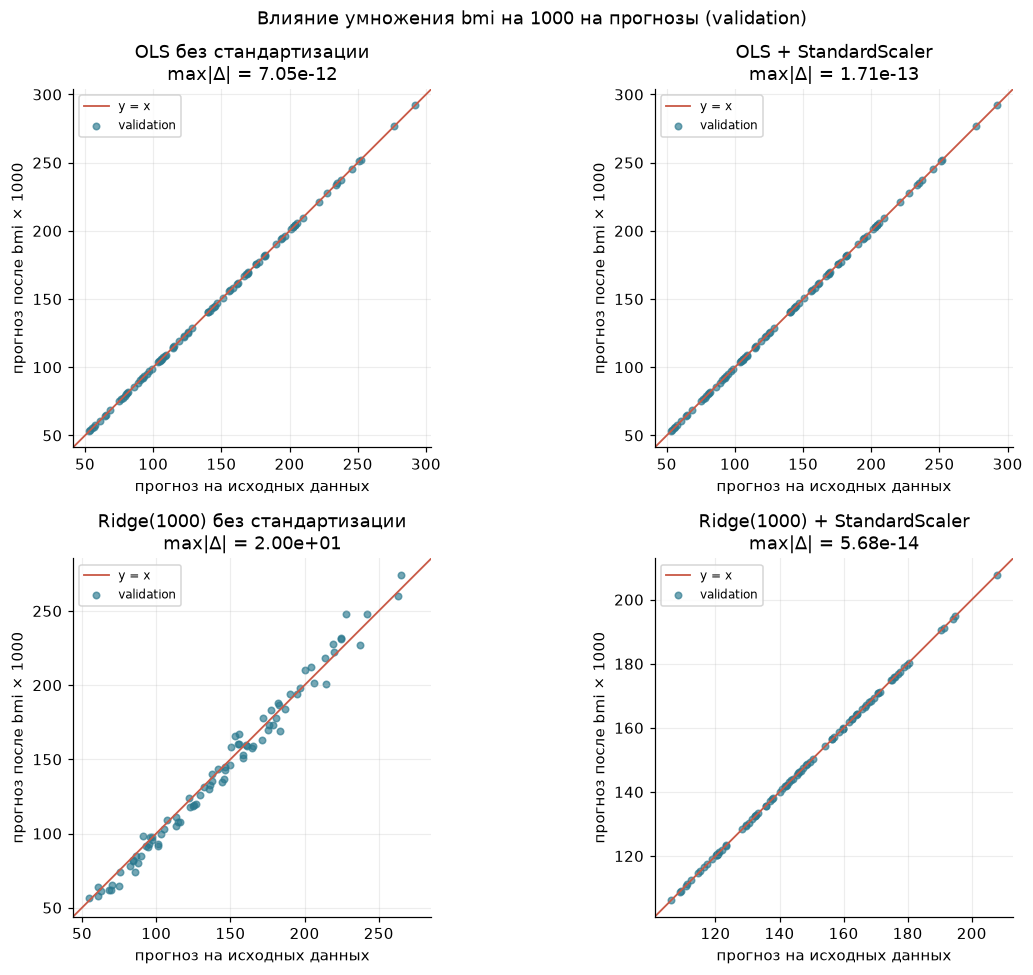

In [5]:
reg_X_train_big = reg_X_train.copy()
reg_X_train_big["bmi"] = reg_X_train_big["bmi"] * 1000
reg_X_valid_big = reg_X_valid.copy()
reg_X_valid_big["bmi"] = reg_X_valid_big["bmi"] * 1000

reg_variants = {
    "OLS без стандартизации": lambda: reg_LinearRegression(),
    "OLS + StandardScaler": lambda: reg_Pipeline(
        [("scaler", reg_StandardScaler()), ("model", reg_LinearRegression())]),
    "Ridge(1000) без стандартизации": lambda: reg_Ridge(alpha=1000),
    "Ridge(1000) + StandardScaler": lambda: reg_Pipeline(
        [("scaler", reg_StandardScaler()), ("model", reg_Ridge(alpha=1000))]),
}

def reg_coef_series(fitted):
    est = fitted[-1] if hasattr(fitted, "steps") else fitted
    return pd.Series(est.coef_, index=reg_X_train.columns)

reg_rows_33, reg_preds_33 = [], {}
for reg_name, reg_factory in reg_variants.items():
    reg_m_plain = reg_factory().fit(reg_X_train, reg_y_train)
    reg_m_big = reg_factory().fit(reg_X_train_big, reg_y_train)
    reg_p_plain = reg_m_plain.predict(reg_X_valid)
    reg_p_big = reg_m_big.predict(reg_X_valid_big)
    reg_preds_33[reg_name] = (reg_p_plain, reg_p_big)
    reg_c_plain, reg_c_big = reg_coef_series(reg_m_plain), reg_coef_series(reg_m_big)
    reg_rows_33.append({
        "вариант": reg_name,
        "max|Δпрогноза|": float(np.max(np.abs(reg_p_big - reg_p_plain))),
        "RMSE исходные": reg_rmse(reg_y_valid, reg_p_plain),
        "RMSE после ×1000": reg_rmse(reg_y_valid, reg_p_big),
        "w_bmi исходные": float(reg_c_plain["bmi"]),
        "w_bmi после ×1000": float(reg_c_big["bmi"]),
        "‖w‖² исходные": float((reg_c_plain ** 2).sum()),
        "‖w‖² после ×1000": float((reg_c_big ** 2).sum()),
    })
reg_table_33 = pd.DataFrame(reg_rows_33)
reg_table_33_show = reg_table_33.round(4)
reg_table_33_show["max|Δпрогноза|"] = reg_table_33["max|Δпрогноза|"].map("{:.2e}".format)
display(reg_table_33_show)

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, (reg_name, (reg_p_plain, reg_p_big)) in zip(axes.flat, reg_preds_33.items()):
    lo = min(reg_p_plain.min(), reg_p_big.min())
    hi = max(reg_p_plain.max(), reg_p_big.max())
    pad = 0.05 * (hi - lo)
    ax.plot([lo - pad, hi + pad], [lo - pad, hi + pad], color="#c95a47", lw=1.2, label="y = x")
    ax.scatter(reg_p_plain, reg_p_big, s=18, alpha=0.65, color="#2a788e", label="validation")
    ax.set(xlim=(lo - pad, hi + pad), ylim=(lo - pad, hi + pad),
           xlabel="прогноз на исходных данных",
           ylabel="прогноз после bmi × 1000",
           title=f"{reg_name}\nmax|Δ| = {np.max(np.abs(reg_p_big - reg_p_plain)):.2e}")
    ax.set_aspect("equal", adjustable="box")
    ax.legend(fontsize=8)
# почему Ridge без стандартизации при alpha=1000 оказался точнее, чем со стандартизацией:
# в пересчёте на стандартизованную шкалу вес штрафа у признака j равен alpha / std_j^2
reg_std = reg_X_train.std(ddof=0)
reg_effect = pd.DataFrame({
    "std признака": reg_std,
    "эфф. вес штрафа alpha/std²": 1000 / reg_std ** 2,
    "OLS, станд. шкала": reg_LinearRegression().fit(reg_X_train, reg_y_train).coef_ * reg_std,
    "Ridge без станд., станд. шкала": reg_Ridge(alpha=1000).fit(reg_X_train, reg_y_train).coef_ * reg_std,
    "Ridge + scaler": reg_Pipeline([("s", reg_StandardScaler()), ("m", reg_Ridge(alpha=1000))]
                                  ).fit(reg_X_train, reg_y_train)[-1].coef_,
})
reg_effect["доля от OLS (без станд.)"] = (reg_effect["Ridge без станд., станд. шкала"]
                                          / reg_effect["OLS, станд. шкала"])
reg_effect["доля от OLS (+ scaler)"] = reg_effect["Ridge + scaler"] / reg_effect["OLS, станд. шкала"]
print("Эффективная сила штрафа по признакам при alpha = 1000:")
display(reg_effect.round(3))

fig.suptitle("Влияние умножения bmi на 1000 на прогнозы (validation)")
fig.tight_layout()
plt.show()

#### Ответ

**Наблюдения.** $\max|\Delta\hat y|$ на validation: OLS без стандартизации $6{,}5\cdot10^{-12}$, OLS + scaler $1{,}8\cdot10^{-13}$, Ridge(1000) + scaler $5{,}7\cdot10^{-14}$ — всё это машинная погрешность, прогнозы совпадают. Ridge(1000) без стандартизации: $\max|\Delta\hat y|=20{,}0$, RMSE $52{,}24\to52{,}33$ — прогнозы реально изменились. Ожидание подтвердилось полностью.

**1. Изменились прогнозы только у Ridge без стандартизации.**

*Почему не меняется OLS.* Прогноз МНК — ортогональная проекция $y$ на линейную оболочку столбцов $X$. Умножение столбца на $a\ne0$ — обратимое преобразование, оболочка от него не меняется, значит не меняется и проекция (1.3). Меняются только координаты в новом базисе: $\tilde w_{\text{bmi}}=w_{\text{bmi}}/1000$, что и видно в таблице ($6{,}3836\to0{,}0064$, отношение ровно 1000).

*Почему не меняется ничто со `StandardScaler`.* Scaler делит столбец на его стандартное отклонение, посчитанное по тем же train-данным. После умножения на 1000 отклонение тоже вырастает в 1000 раз, поэтому стандартизованная матрица совпадает с исходной с точностью до округления — модель обучается буквально на тех же числах.

*Почему меняется Ridge без стандартизации.* Ridge решает другую задачу: среди всех способов записать одно и то же предсказание он предпочитает тот, у которого меньше $\|w\|_2$, а эта величина зависит от единиц измерения. Увеличив масштаб `bmi`, мы сделали «дешёвым» признак, который раньше был дорогим, и оптимум сместился.

**2. Коэффициент и штраф.** Чтобы сохранить предсказание, коэффициент при `bmi` нужно разделить на 1000. В эксперименте он ушёл с 5,635 до 0,00725 (отношение 777, а не ровно 1000, потому что модель дополнительно перестроила остальные коэффициенты). Вклад этого коэффициента в штраф падает примерно в $10^6$ раз: суммарная $\|w\|_2^2$ упала с 40,07 до 7,00. То есть преобразование признака молча сообщило модели: «`bmi` теперь бесплатный, а остальные признаки по-прежнему дорогие». Это и есть неинвариантность штрафа из 1.3: $\|\tilde w\|_2^2=\|w\|_2^2-w_j^2(1-a^{-2})$.

**3. Роль стандартизации и её пределы.** Стандартизация **фиксирует смысл `alpha`**: единое число штрафует все координаты одинаково, и это осмысленно, только если координаты соизмеримы. Без неё величина `alpha` неявно зависит от того, в каких единицах кто-то записал таблицу.

**Но снижение ошибки при фиксированном `alpha` она не гарантирует — и в нашем эксперименте не даёт.** Прямой контрпример из той же таблицы: при `alpha=1000` Ridge со scaler имеет validation RMSE 61,96, а Ridge без scaler — 52,24, то есть **нестандартизованный вариант точнее**. Причина видна в таблице эффективных весов: в пересчёте на стандартизованную шкалу признак $j$ штрафуется с весом $\mathrm{alpha}/s_j^2$. У `s1` и `s2` ($s_j\approx35$ и 31) этот вес равен 0,8 и 1,1 — они практически не штрафуются и сохраняют коэффициенты уровня OLS; у `bmi` и `bp` вес 51 и 5, они сохраняют 88% и 98% от OLS. Зато `sex`, `s4`, `s5` с маленькими $s_j$ получают вес 600–4000 и уничтожаются (остаётся 5%, 3% и 1% от OLS). Нестандартизованный Ridge при `alpha=1000` — это, по сути, **гораздо более слабая регуляризация для тех признаков, которые несут основную часть подгонки**, поэтому он ближе к OLS, а OLS в этой задаче лучше (3.4).

Вывод: сравнение «со scaler против без scaler при одинаковом `alpha`» сравнивает две разные силы регуляризации и ничего не говорит о пользе масштабирования. Стандартизация делает `alpha` осмысленным и сопоставимым между признаками; после неё `alpha` нужно подбирать заново.

### 3.4

На исходных признаках обучите модели в `Pipeline` со `StandardScaler`:

- Ridge: `alpha = [0.1, 1, 10, 100, 1000, 10000]`;
- Lasso: `alpha = [0.01, 0.1, 1, 3, 10, 30, 100]`, `max_iter=20000`.

Для каждого значения сохраните модель, коэффициенты, train RMSE и validation RMSE.
Постройте рисунок из четырёх панелей: в верхнем ряду — зависимости ошибок
от `alpha` для двух моделей, в нижнем — зависимости их коэффициентов от `alpha`.
Используйте логарифмическую ось `alpha` и линию нуля на графиках коэффициентов.

1. Как регуляризация влияет на train RMSE и validation RMSE? Объясните форму полученных кривых.
2. Проверьте по графикам утверждение: «При усилении Ridge-регуляризации каждый коэффициент не возрастает по модулю». Объясните результат и его связь с пунктом 1.2. Сравните поведение с Lasso: есть ли нулевые коэффициенты и что можно заключить о соответствующих признаках?
3. По документации [Ridge](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html) и [Lasso](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Lasso.html) установите связь `alpha` с $\lambda$ из задачи 1. Можно ли сравнивать силу двух видов регуляризации по одинаковому числу `alpha`?
4. Интерпретируйте знак и величину коэффициента `bmi` у Lasso при `alpha=1`. Можно ли считать модуль коэффициента мерой важности признака? Обоснуйте ответ.

**Ожидаемый эффект (записано до опыта).** train RMSE будет монотонно расти с `alpha` (следствие 1.2), validation RMSE пройдёт через минимум или — если OLS не переобучается — тоже будет только расти; коэффициенты Ridge станут плавно сжиматься, а коэффициенты Lasso будут по одному обращаться в точный ноль.

Ridge: ошибки


,train RMSE,validation RMSE
alpha,,
0.1,54.285,49.156
1.0,54.297,49.203
10.0,54.395,49.373
100.0,55.440,50.815
1000.0,64.442,61.959
10000.0,74.783,73.407


Ridge: коэффициенты


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0.1,0.87,-10.77,28.37,17.34,-30.48,16.07,0.22,6.69,27.93,1.50
1.0,0.99,-10.68,28.44,17.24,-23.44,10.56,-2.81,5.87,25.12,1.57
10.0,1.31,-10.12,27.85,16.67,-8.58,-0.95,-8.79,4.68,18.78,2.09
100.0,1.84,-6.66,21.48,13.34,-2.30,-3.17,-9.16,5.42,13.59,4.41
1000.0,1.67,-0.67,7.68,5.24,0.80,0.39,-4.43,3.87,5.80,3.70
10000.0,0.35,0.05,1.16,0.83,0.31,0.26,-0.75,0.77,0.97,0.70


Lasso: ошибки


,train RMSE,validation RMSE
alpha,,
0.01,54.285,49.157
0.10,54.302,49.204
1.00,54.473,49.525
3.00,55.022,50.726
10.00,57.386,53.821
30.00,67.665,66.029
100.00,77.331,76.161


Lasso: коэффициенты


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0.01,0.86,-10.76,28.38,17.34,-30.11,15.83,0.00,6.55,27.82,1.48
0.10,0.90,-10.52,28.59,17.19,-21.67,9.20,-3.45,5.54,24.57,1.47
1.00,0.11,-8.55,28.76,16.26,-5.82,-0.00,-10.84,0.00,19.28,0.97
3.00,0.00,-5.32,28.20,14.38,-0.00,-1.35,-10.47,0.00,15.77,0.00
10.00,0.00,-0.00,26.20,8.59,-0.00,-0.00,-3.97,0.00,13.18,0.00
30.00,0.00,0.00,15.68,0.00,0.00,0.00,-0.00,0.00,2.79,0.00
100.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


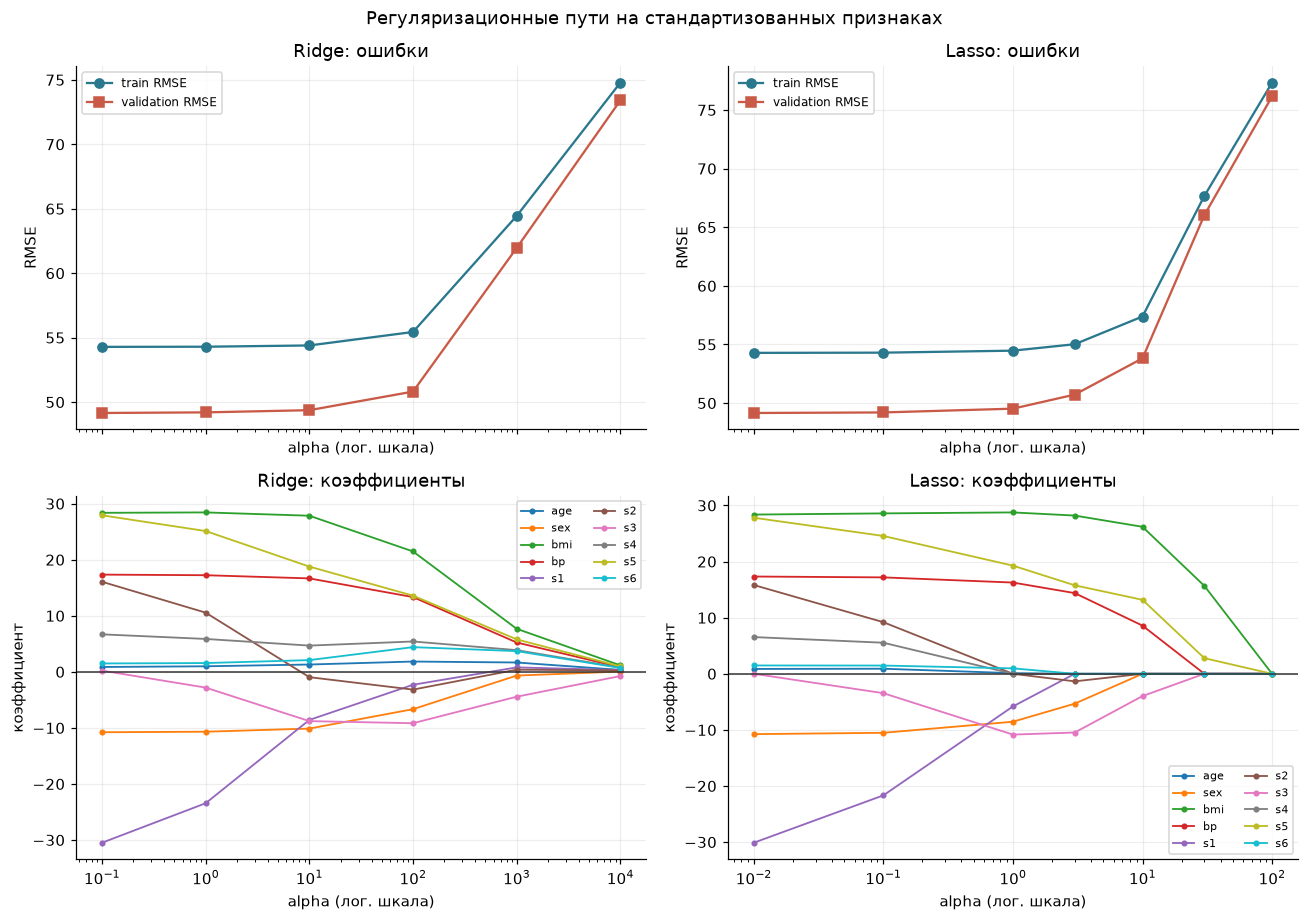

Евклидова норма вектора коэффициентов Ridge:


,Ridge ‖w‖₂
0.1,56.89
1.0,50.57
10.0,41.09
100.0,31.93
1000.0,13.13
10000.0,2.22


Где |коэффициент| Ridge РАСТЁТ при увеличении alpha (прирост модуля):


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
1.0,0.122,NaN,0.072,NaN,NaN,NaN,2.588,NaN,NaN,0.073
10.0,0.317,NaN,NaN,NaN,NaN,NaN,5.976,NaN,NaN,0.525
100.0,0.531,NaN,NaN,NaN,NaN,2.219,0.376,0.735,NaN,2.313


Число нулевых коэффициентов Lasso:


,нулевых из 10
0.01,0
0.10,0
1.00,2
3.00,4
10.00,6
30.00,8
100.00,10


Коэффициенты Lasso при alpha = 1 и стандартные отклонения признаков:


,w (станд. шкала),std признака на train,w в исходных единицах
age,0.112,12.980,0.009
sex,-8.545,0.499,-17.112
bmi,28.764,4.450,6.464
bp,16.263,13.973,1.164
s1,-5.822,35.052,-0.166
s2,-0.000,30.615,-0.000
s3,-10.836,13.147,-0.824
s4,0.000,1.296,0.000
s5,19.278,0.525,36.740
s6,0.970,11.359,0.085


In [6]:
reg_ridge_alphas = [0.1, 1, 10, 100, 1000, 10000]
reg_lasso_alphas = [0.01, 0.1, 1, 3, 10, 30, 100]

def reg_fit_path(kind, alphas):
    scores, coefs, models = [], [], {}
    for alpha in alphas:
        estimator = (reg_Ridge(alpha=alpha) if kind == "ridge"
                     else reg_Lasso(alpha=alpha, max_iter=20000))
        pipe = reg_Pipeline([("scaler", reg_StandardScaler()),
                             ("model", estimator)]).fit(reg_X_train, reg_y_train)
        models[alpha] = pipe
        scores.append({"alpha": alpha,
                       "train RMSE": reg_rmse(reg_y_train, pipe.predict(reg_X_train)),
                       "validation RMSE": reg_rmse(reg_y_valid, pipe.predict(reg_X_valid))})
        coefs.append(pd.Series(pipe[-1].coef_, index=reg_X_train.columns, name=alpha))
    return pd.DataFrame(scores).set_index("alpha"), pd.DataFrame(coefs), models

reg_ridge_scores, reg_ridge_coefs, reg_ridge_models = reg_fit_path("ridge", reg_ridge_alphas)
reg_lasso_scores, reg_lasso_coefs, reg_lasso_models = reg_fit_path("lasso", reg_lasso_alphas)

print("Ridge: ошибки"); display(reg_ridge_scores.round(3))
print("Ridge: коэффициенты"); display(reg_ridge_coefs.round(2))
print("Lasso: ошибки"); display(reg_lasso_scores.round(3))
print("Lasso: коэффициенты"); display(reg_lasso_coefs.round(2))

fig, axes = plt.subplots(2, 2, figsize=(12, 8.5), sharex="col")
for col, (name, scores, coefs) in enumerate(
        [("Ridge", reg_ridge_scores, reg_ridge_coefs),
         ("Lasso", reg_lasso_scores, reg_lasso_coefs)]):
    ax = axes[0, col]
    ax.plot(scores.index, scores["train RMSE"], "o-", color="#2a788e", label="train RMSE")
    ax.plot(scores.index, scores["validation RMSE"], "s-", color="#c95a47", label="validation RMSE")
    ax.set(xscale="log", xlabel="alpha (лог. шкала)", ylabel="RMSE", title=f"{name}: ошибки")
    ax.legend(fontsize=8)
    ax = axes[1, col]
    for feature in coefs.columns:
        ax.plot(coefs.index, coefs[feature], "o-", ms=3, lw=1.2, label=feature)
    ax.axhline(0, color="#333333", lw=1)
    ax.set(xscale="log", xlabel="alpha (лог. шкала)", ylabel="коэффициент",
           title=f"{name}: коэффициенты")
    ax.legend(fontsize=7, ncol=2)
fig.suptitle("Регуляризационные пути на стандартизованных признаках")
fig.tight_layout()
plt.show()

reg_norms = pd.DataFrame({
    "Ridge ‖w‖₂": np.sqrt((reg_ridge_coefs ** 2).sum(axis=1)),
})
print("Евклидова норма вектора коэффициентов Ridge:")
display(reg_norms.round(2))

reg_ridge_growth = reg_ridge_coefs.abs().diff()
print("Где |коэффициент| Ridge РАСТЁТ при увеличении alpha (прирост модуля):")
display(reg_ridge_growth[reg_ridge_growth > 1e-9].dropna(how="all").round(3))

print("Число нулевых коэффициентов Lasso:")
display((reg_lasso_coefs.abs() < 1e-8).sum(axis=1).to_frame("нулевых из 10"))

print("Коэффициенты Lasso при alpha = 1 и стандартные отклонения признаков:")
display(pd.DataFrame({"w (станд. шкала)": reg_lasso_coefs.loc[1].round(3),
                      "std признака на train": reg_X_train.std().round(3),
                      "w в исходных единицах": (reg_lasso_coefs.loc[1] / reg_X_train.std()).round(3)}))

#### Ответ

**1. Влияние регуляризации на ошибки.**

train RMSE монотонно растёт у обеих моделей: Ridge $54{,}285\to74{,}783$, Lasso $54{,}285\to77{,}331$. Это ровно утверждение 1.2 (для Lasso оно доказывается тем же двухточечным аргументом — в доказательстве нигде не использовался конкретный вид штрафа). Минимум validation RMSE достигается на **левом краю** сетки: Ridge 49,156 при `alpha=0,1`, Lasso 49,157 при `alpha=0,01`, и дальше ошибка только растёт.

Форма кривых: классическая U-образная кривая здесь видна **только своей правой ветвью**. Причина содержательная, а не техническая: при 265 объектах на 10 признаков OLS не переобучается, дисперсия оценок и без того мала, поэтому обменивать её на смещение нечем — регуляризация добавляет только смещение. Правая часть кривой — вырождение модели: при `alpha=10000` Ridge даёт validation RMSE 73,4, приближаясь к уровню Dummy (76,2), а Lasso при `alpha=100` достигает его точно. У Lasso это видно буквально: при `alpha=100` все десять коэффициентов равны нулю, остаётся один свободный член, и validation RMSE равна 76,161 — в точности значение Dummy из 3.2. Это и есть предел из п. 1.4: при нештрафуемом свободном члене бесконечная регуляризация даёт модель-среднее, а не нулевую модель.

**2. Проверка утверждения «при усилении Ridge каждый коэффициент не возрастает по модулю».**

**Утверждение неверно, и график это показывает.** Контрпримеры прямо в таблице коэффициентов Ridge: при росте `alpha` с 0,1 до 100 коэффициент $w_{s_3}$ идёт $0{,}22\to-2{,}81\to-8{,}79\to-9{,}16$, то есть **модуль вырос более чем в 40 раз**; аналогично $w_{\text{age}}$: $0{,}87\to1{,}84$ и $w_{s_6}$: $1{,}50\to4{,}41$; у $w_{s_2}$ модуль растёт на участке `alpha` от 10 до 100.

**Противоречия с 1.2 нет.** В 1.2 доказана монотонность **нормы всего вектора**, а не отдельных координат, и численно она выполняется безупречно: $\|w\|_2=56{,}89,\,50{,}57,\,41{,}09,\,31{,}93,\,13{,}13,\,2{,}22$. Покоординатная монотонность — дополнительное, более сильное утверждение, и оно верно лишь в ортогональном дизайне, где задача распадается на независимые координаты и решение имеет вид $c_j/(1+\lambda)$ (1.1). В реальных данных признаки коррелированы, и по формуле из 1.2 сжатие происходит **вдоль главных осей** $v_i$, а не вдоль осей координат; проекция сжимающегося вектора на фиксированную ось координат вполне может временно расти. Содержательно: подавив гигантскую противоположную пару $w_{s_1}=-30{,}5$, $w_{s_2}=+16{,}1$ (которые почти гасили друг друга), модель освобождает место для `s3`, несущего тот же сигнал дешевле по норме.

**Lasso: нули есть, и их число растёт монотонно** — 0, 0, 2, 4, 6, 8, 10 при `alpha` = 0,01; 0,1; 1; 3; 10; 30; 100. Это прямое проявление мягкого порога из 1.1: координата ровно нулевая, пока соответствующая «сила» не превосходит $\lambda$. Порядок выбывания: при `alpha=1` обнуляются `s2` и `s4`; при `alpha=3` к ним добавляются `age`, `s1`, `s6`, а `s2` **возвращается** в модель с коэффициентом $-1{,}35$; последними, при `alpha=30`, держатся только `bmi` и `s5`. Возвращение `s2` — отдельная иллюстрация к п. 2: монотонно растёт число нулей, а не судьба каждого коэффициента по отдельности.

Что отсюда можно заключить о признаках: обнулённые признаки **не несут информации сверх той, что уже содержится в оставленных**. Это утверждение о структуре избыточности данного набора, а не о биологической бесполезности: `s2` обнулён при $r(s_1,s_2)=0{,}89$, а `s4` — при $r(s_3,s_4)=-0{,}73$. В группе почти коллинеарных признаков Lasso **произвольно выбирает одного представителя** и зануляет остальных, и этот выбор неустойчив — малое изменение данных может поменять выбранного. Поэтому список ненулевых коэффициентов нельзя читать как «список важных признаков».

**3. Связь `alpha` с $\lambda$ из задачи 1.**

По документации `Ridge` минимизирует $\|y-Xw\|_2^2+\mathrm{alpha}\cdot\|w\|_2^2$. Наша $L_{\mathrm{Ridge}}=\frac1{2n}\|y-Xw\|^2+\frac\lambda2\|w\|^2$; умножив её на $2n$ (что не меняет точку минимума), получаем $\|y-Xw\|^2+n\lambda\|w\|^2$. Значит

$$\mathrm{alpha}_{\mathrm{Ridge}}=n\lambda,\qquad \lambda=\frac{\mathrm{alpha}}{n}\;(n=265).$$

Например, `alpha=10` отвечает $\lambda\approx0{,}038$.

По документации `Lasso` минимизирует $\frac1{2n}\|y-Xw\|_2^2+\mathrm{alpha}\cdot\|w\|_1$ — это **в точности** наша $L_{\mathrm{Lasso}}$, поэтому $\mathrm{alpha}_{\mathrm{Lasso}}=\lambda$ без поправок.

**Сравнивать силу двух регуляризаций по одинаковому числу `alpha` нельзя**, и по двум независимым причинам. Во-первых, нормировки функционалов разные: одно и то же число `alpha` отвечает $\lambda$, отличающимся в $n=265$ раз. Во-вторых — и это важнее — даже после приведения к общей нормировке величины несопоставимы: $\lambda$ умножается на $\|w\|_2^2$ в одном случае и на $\|w\|_1$ в другом, то есть имеет **разную размерность** по $w$, и геометрия ограничения другая (шар против октаэдра). Корректное сравнение — при равном значении общей величины: одинаковой $\|w\|_2$ решения, одинаковом числе эффективных степеней свободы или одинаковой train RMSE. В нашем прогоне `alpha=10` у Ridge даёт validation RMSE 49,37, а `alpha=10` у Lasso — 53,82: это совершенно разные точки пути.

**4. Коэффициент `bmi` у Lasso при `alpha=1`.**

$w_{\text{bmi}}=28{,}76$ в стандартизованной шкале — **наибольший по модулю** среди всех коэффициентов этой модели. Знак положительный: больший индекс массы тела связан с более высоким значением показателя прогрессирования. Величина читается так: увеличение `bmi` на одно стандартное отклонение train (4,45 кг/м²) соответствует росту прогноза на 28,8 единицы target при неизменных прочих признаках; в исходных единицах это $28{,}76/4{,}45=6{,}46$ единицы target на один кг/м².

**Можно ли считать модуль коэффициента мерой важности признака?** В общем случае нет; при соблюдении условий — очень ограниченно.

* **Зависимость от масштаба.** Модуль коэффициента имеет размерность «ответ на единицу признака», поэтому сравнение модулей осмысленно только после приведения признаков к общей шкале. У нас стандартизация есть, но в исходных единицах картина другая: там $w_{s_5}=36{,}74$ против $w_{\text{bmi}}=6{,}46$, и «важнейшим» оказался бы `s5` — просто потому, что его стандартное отклонение 0,52.
* **Коррелированность.** Как показано в п. 2, Lasso обнулил `s2` и `s4` не потому, что они неинформативны, а потому, что они дублируют `s1` и `s3`/`s5`. Распределение общего эффекта между коррелированными признаками неустойчиво, и модуль каждого из них по отдельности не имеет самостоятельного смысла.
* **Условность.** Коэффициент — условная ассоциация при фиксированном наборе признаков; он меняется при добавлении или удалении признаков и не является причинным эффектом (3.1.4).
* **Смещение от штрафа.** Регуляризация сжимает коэффициенты к нулю, причём неравномерно по признакам, так что модули систематически занижены и искажены.

Более честные меры важности: permutation importance на validation (падение качества при случайной перестановке признака) или прямое сравнение ошибки моделей с признаком и без него. Они измеряют вклад в предсказание, а не величину параметра в выбранной параметризации.

### 3.5

По результатам 3.2 и 3.4 выберите OLS или одну из моделей Ridge/Lasso
со `StandardScaler`. Зафиксируйте и обоснуйте выбор до обращения к test.

Вычислите test RMSE выбранной обученной модели. Постройте график фактических
значений против прогнозов с диагональю либо остатков против прогнозов с линией нуля.

Интерпретируйте график и укажите ограничение модели или проведённого эксперимента.

,модель,validation RMSE,bootstrap SE,Δ к OLS,95% ДИ для Δ
0,OLS + StandardScaler,49.150,4.163,0.000,"[0.0, 0.0]"
1,Ridge(alpha=0.1),49.156,4.159,0.006,"[-0.022, 0.035]"
2,Ridge(alpha=10),49.373,4.036,0.223,"[-0.501, 0.989]"
3,Lasso(alpha=0.01),49.157,4.158,0.008,"[-0.027, 0.045]"


Зафиксированная модель: OLS + StandardScaler (переобучения на train+validation нет)


,модель,test RMSE
0,DummyRegressor(mean),76.91
1,OLS + StandardScaler,56.97


validation RMSE этой же модели: 49.15
Остатки на test: среднее = 13.01, std = 55.46, corr(прогноз, |остаток|) = 0.184


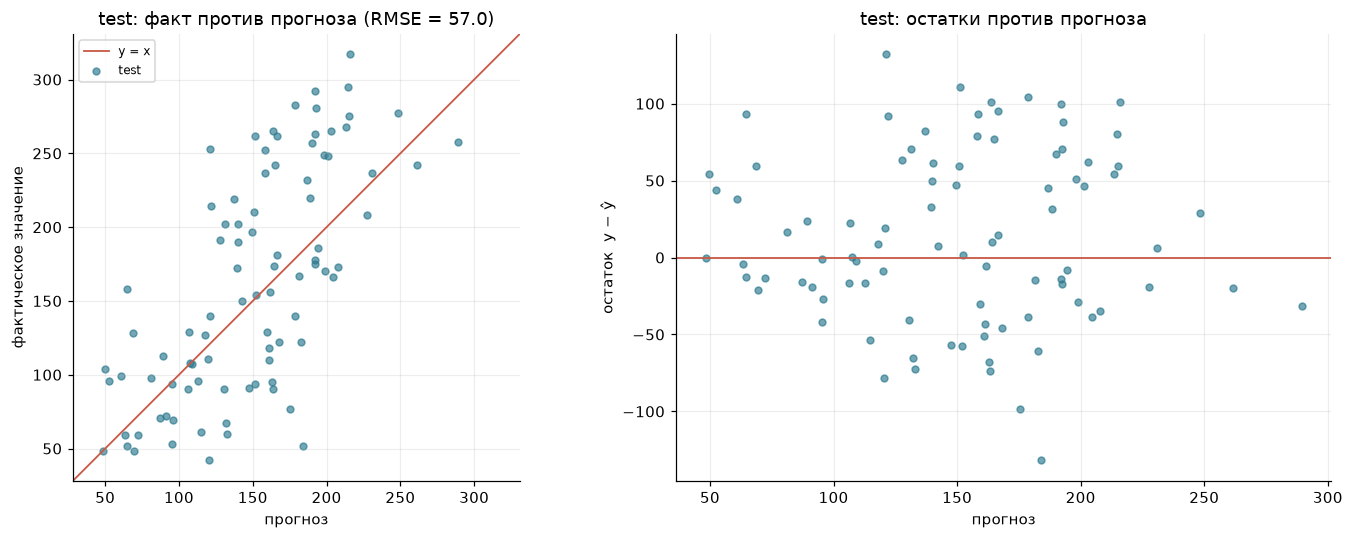

In [7]:
# --- насколько различимы кандидаты на validation: бутстрэп по validation ---
reg_candidates = {
    "OLS + StandardScaler": reg_ols,
    "Ridge(alpha=0.1)": reg_ridge_models[0.1],
    "Ridge(alpha=10)": reg_ridge_models[10],
    "Lasso(alpha=0.01)": reg_lasso_models[0.01],
}
reg_val_pred = {k: m.predict(reg_X_valid) for k, m in reg_candidates.items()}
reg_rng = np.random.default_rng(SEED)
reg_y_valid_arr = np.asarray(reg_y_valid)
reg_boot_idx = reg_rng.integers(0, len(reg_y_valid_arr), size=(5000, len(reg_y_valid_arr)))

def reg_boot_rmse(pred):
    return np.sqrt(np.mean((reg_y_valid_arr[reg_boot_idx] - pred[reg_boot_idx]) ** 2, axis=1))

reg_boot = {k: reg_boot_rmse(p) for k, p in reg_val_pred.items()}
reg_table_35 = pd.DataFrame([
    {"модель": k,
     "validation RMSE": reg_rmse(reg_y_valid, p),
     "bootstrap SE": float(np.std(reg_boot[k])),
     "Δ к OLS": reg_rmse(reg_y_valid, p) - reg_rmse(reg_y_valid, reg_val_pred["OLS + StandardScaler"]),
     "95% ДИ для Δ": np.round(np.percentile(reg_boot[k] - reg_boot["OLS + StandardScaler"], [2.5, 97.5]), 3).tolist()}
    for k, p in reg_val_pred.items()
])
display(reg_table_35.round(3))

# --- выбор зафиксирован: OLS + StandardScaler ---
reg_final_name = "OLS + StandardScaler"
reg_final_model = reg_candidates[reg_final_name]
print(f"Зафиксированная модель: {reg_final_name} (переобучения на train+validation нет)")

# --- единственное обращение к test ---
reg_test_pred = reg_final_model.predict(reg_X_test)
reg_test_rmse = reg_rmse(reg_y_test, reg_test_pred)
reg_test_dummy_rmse = reg_rmse(reg_y_test, reg_dummy.predict(reg_X_test))
display(pd.DataFrame([
    {"модель": "DummyRegressor(mean)", "test RMSE": reg_test_dummy_rmse},
    {"модель": reg_final_name, "test RMSE": reg_test_rmse},
]).round(2))
print(f"validation RMSE этой же модели: {reg_rmse(reg_y_valid, reg_val_pred[reg_final_name]):.2f}")

reg_resid = np.asarray(reg_y_test) - reg_test_pred
print(f"Остатки на test: среднее = {reg_resid.mean():.2f}, std = {reg_resid.std():.2f}, "
      f"corr(прогноз, |остаток|) = {np.corrcoef(reg_test_pred, np.abs(reg_resid))[0, 1]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
lo = min(reg_test_pred.min(), np.min(reg_y_test))
hi = max(reg_test_pred.max(), np.max(reg_y_test))
pad = 0.05 * (hi - lo)
axes[0].plot([lo - pad, hi + pad], [lo - pad, hi + pad], color="#c95a47", lw=1.2, label="y = x")
axes[0].scatter(reg_test_pred, reg_y_test, s=20, alpha=0.65, color="#2a788e", label="test")
axes[0].set(xlabel="прогноз", ylabel="фактическое значение",
            xlim=(lo - pad, hi + pad), ylim=(lo - pad, hi + pad),
            title=f"test: факт против прогноза (RMSE = {reg_test_rmse:.1f})")
axes[0].set_aspect("equal", adjustable="box")
axes[0].legend(fontsize=8)
axes[1].axhline(0, color="#c95a47", lw=1.2)
axes[1].scatter(reg_test_pred, reg_resid, s=20, alpha=0.65, color="#2a788e")
axes[1].set(xlabel="прогноз", ylabel="остаток  y − ŷ", title="test: остатки против прогноза")
fig.tight_layout()
plt.show()

#### Ответ

**Выбор, зафиксированный до обращения к test.**

По validation RMSE кандидаты расположились так: OLS + StandardScaler — 49,150; Ridge(`alpha=0,1`) — 49,156; Lasso(`alpha=0,01`) — 49,157; Ridge(`alpha=10`) — 49,373. Формальный минимум у OLS.

Но прежде чем опираться на третий знак, оценим шум. Бутстрэп по validation (5000 выборок с возвращением) даёт стандартную ошибку самой RMSE $\approx4{,}16$, а 95%-й доверительный интервал для разности «Ridge(0,1) минус OLS» равен $[-0{,}022;\,0{,}035]$ — он содержит ноль, и сама разность 0,006 на три порядка меньше неопределённости оценки. Три верхние модели **статистически неразличимы**.

Поэтому выбор опирается на два соображения: (1) у OLS формально минимальная validation RMSE; (2) среди неразличимых по качеству моделей разумно брать ту, у которой нет гиперпараметра, подобранного по той же validation, — её оценка качества не смещена отбором. **Выбрана модель `OLS + StandardScaler`**, обученная только на train; переобучения на train + validation не производится.

(Оговорка: если бы целью была интерпретация коэффициентов, а не прогноз, я бы взял Ridge с `alpha≈10` — при той же ошибке он подавляет неустойчивую пару `s1`/`s2` из 3.4.2.)

**Результат на test:** RMSE $=56{,}97$ против 76,91 у Dummy. На validation та же модель давала 49,15, то есть на test она на 7,8 единицы хуже.

**Интерпретация графиков.**

* Облако точек идёт вдоль диагонали, систематического искривления не видно — линейное приближение график не опровергает.
* Остатки имеют положительное среднее $+13{,}0$: на test модель **систематически занижает** прогноз. Это свойство конкретного разбиения (среднее target на test выше обучающего), а не метода.
* Разброс остатков растёт вместе с прогнозом: $\mathrm{corr}(\hat y,|y-\hat y|)=0{,}184$, и в правой части облако заметно шире. Это **гетероскедастичность**: для тяжёлых пациентов исход менее предсказуем. Обычная МНК-оценка предполагает постоянную дисперсию, так что доверительные интервалы, построенные по стандартным формулам, здесь были бы некорректны.
* Диапазон прогнозов (48,3–289,3) уже диапазона фактических значений (42–317) — характерное **сжатие размаха** линейной модели: она предсказывает условное среднее и потому не воспроизводит крайние значения.

**Ограничения.**

* Одно фиксированное разбиение: 88 объектов в validation и 89 в test. Стандартная ошибка RMSE $\approx4$ единицы, поэтому разница между 49,15 и 56,97 — это примерно два стандартных отклонения и в значительной мере шум разбиения, а не доказанное переобучение. Корректный вывод требует кросс-валидации или повторения на нескольких `random_state`.
* Оценка на test несмещена только для **зафиксированного** решения и допускает единственное использование; любая переподгонка по его результатам это свойство уничтожает.
* RMSE $\approx57$ при фактических значениях 42–317 — модель улавливает групповой тренд, но для индивидуального прогноза недостаточно точна.
* Все выводы ассоциативные: коэффициенты нельзя читать как причинные эффекты (3.1.4), а почти коллинеарные группы `s1`–`s2` и `s3`–`s4` оставлены как есть.

## Задача 4. Классификация

Используйте набор Wisconsin Diagnostic Breast Cancer. Он содержит 30 числовых
характеристик клеточных ядер. Во всех пунктах используйте только `mean radius`
и `mean texture`. Целевая переменная перекодирована:
`1 = malignant` (злокачественная опухоль), `0 = benign` (доброкачественная опухоль).

Рассматриваются четыре метода:

- логистическая регрессия — модель вероятности класса с сигмоидой от линейной комбинации признаков;
- kNN — классификация по меткам ближайших соседей;
- SVM с RBF-ядром — метод опорных векторов с гауссовым ядром;
- дерево решений — последовательность разбиений по значениям признаков.

Стратифицированное разбиение train / validation / test — 60 / 20 / 20%.
Финальная оценка на test выполняется в пункте 4.5.

[Описание данных](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html).

In [8]:
from IPython.display import Markdown as cls_Markdown
from sklearn.datasets import load_breast_cancer as cls_load_data
from sklearn.dummy import DummyClassifier as cls_DummyClassifier
from sklearn.linear_model import LogisticRegression as cls_LogisticRegression
from sklearn.neighbors import KNeighborsClassifier as cls_KNeighborsClassifier
from sklearn.svm import SVC as cls_SVC
from sklearn.tree import DecisionTreeClassifier as cls_DecisionTreeClassifier
from sklearn.pipeline import Pipeline as cls_Pipeline
from sklearn.preprocessing import StandardScaler as cls_StandardScaler
from sklearn.model_selection import train_test_split as cls_train_test_split
from sklearn.metrics import (
    balanced_accuracy_score as cls_balanced_accuracy_score,
    precision_score as cls_precision_score,
    recall_score as cls_recall_score,
    confusion_matrix as cls_confusion_matrix,
    ConfusionMatrixDisplay as cls_ConfusionMatrixDisplay,
)

cls_data = cls_load_data(as_frame=True)
cls_features = ["mean radius", "mean texture"]
cls_X = cls_data.data[cls_features].copy()
cls_y = (cls_data.target == 0).astype(int).rename("malignant")
cls_X_dev, cls_X_test, cls_y_dev, cls_y_test = cls_train_test_split(
    cls_X, cls_y, test_size=0.20, stratify=cls_y, random_state=SEED
)
cls_X_train, cls_X_val, cls_y_train, cls_y_val = cls_train_test_split(
    cls_X_dev, cls_y_dev, test_size=0.25, stratify=cls_y_dev, random_state=SEED
)
assert set(cls_X_train.index).isdisjoint(cls_X_val.index)
assert set(cls_X_train.index).isdisjoint(cls_X_test.index)
assert set(cls_X_val.index).isdisjoint(cls_X_test.index)
print("Число объектов train / validation / test:",
      len(cls_X_train), len(cls_X_val), len(cls_X_test))

Число объектов train / validation / test: 341 114 114


Функция `cls_plot_boundaries(models, titles=None, radius_multipliers=None, mark_errors=True)`
принимает словарь «название → обученная модель» и строит области предсказанных классов.
На графике отображаются train-объекты и, при `mark_errors=True`, ошибки validation.
`titles` задаёт подписи, `radius_multipliers` — множители радиуса на входе каждой модели.
Координаты графика соответствуют исходным единицам признаков.

In [9]:
cls_colors = {0: "#2a788e", 1: "#c95a47"}
cls_names = {0: "benign (0)", 1: "malignant (1)"}
cls_low = cls_X_train.min() - 0.06 * (cls_X_train.max() - cls_X_train.min())
cls_high = cls_X_train.max() + 0.06 * (cls_X_train.max() - cls_X_train.min())
cls_xx, cls_yy = np.meshgrid(
    np.linspace(cls_low.iloc[0], cls_high.iloc[0], 180),
    np.linspace(cls_low.iloc[1], cls_high.iloc[1], 180),
)
cls_grid = pd.DataFrame({cls_features[0]: cls_xx.ravel(), cls_features[1]: cls_yy.ravel()})

def cls_draw_boundary(model, ax, title, radius_multiplier=1, mark_errors=True):
    grid = cls_grid.copy()
    grid[cls_features[0]] *= radius_multiplier
    pred = model.predict(grid).reshape(cls_xx.shape)
    ax.contourf(cls_xx, cls_yy, pred, levels=[-0.5, 0.5, 1.5],
                colors=[cls_colors[0], cls_colors[1]], alpha=0.19)
    if hasattr(model, "decision_function"):
        score = model.decision_function(grid).reshape(cls_xx.shape)
        ax.contour(cls_xx, cls_yy, score, levels=[0], colors="#333333", linewidths=1)
    else:
        ax.contour(cls_xx, cls_yy, pred, levels=[0.5], colors="#333333", linewidths=1)
    for label in [0, 1]:
        mask = cls_y_train == label
        ax.scatter(cls_X_train.loc[mask, cls_features[0]],
                   cls_X_train.loc[mask, cls_features[1]],
                   color=cls_colors[label], s=15, alpha=0.65, label=cls_names[label])
    if mark_errors:
        val = cls_X_val.copy()
        val[cls_features[0]] *= radius_multiplier
        wrong = model.predict(val) != cls_y_val
        ax.scatter(cls_X_val.loc[wrong, cls_features[0]], cls_X_val.loc[wrong, cls_features[1]],
                   color="black", marker="x", s=30, linewidths=1, label="ошибка validation")
    ax.set(xlabel=cls_features[0], ylabel=cls_features[1], title=title,
           xlim=(cls_low.iloc[0], cls_high.iloc[0]),
           ylim=(cls_low.iloc[1], cls_high.iloc[1]))


def cls_plot_boundaries(models, titles=None, radius_multipliers=None, mark_errors=True):
    # models: словарь «название → обученная модель»; функция ничего не обучает.
    if not 1 <= len(models) <= 4:
        raise ValueError("Передайте от одной до четырёх обученных моделей")
    titles = {} if titles is None else titles
    radius_multipliers = {} if radius_multipliers is None else radius_multipliers
    columns = min(2, len(models))
    rows = (len(models) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(5.5 * columns, 4 * rows),
                             sharex=True, sharey=True, squeeze=False)
    for ax, (name, model) in zip(axes.flat, models.items()):
        cls_draw_boundary(model, ax, titles.get(name, name),
                          radius_multiplier=radius_multipliers.get(name, 1),
                          mark_errors=mark_errors)
    for ax in list(axes.flat)[len(models):]:
        ax.set_visible(False)
    axes.flat[0].legend(fontsize=8)
    fig.suptitle("Точки — train" + ("; крестики — ошибки validation" if mark_errors else ""))
    fig.tight_layout()
    plt.show()

### 4.1

На train определите диапазоны двух признаков и доли классов.
Постройте диаграмму `mean radius` × `mean texture` с цветом по классу.

1. В каких областях ожидаете ошибки классификатора по этим двум признакам? Обоснуйте ответ.
2. Вычислите accuracy, recall класса 1 и balanced accuracy для правила «всегда класс большинства». Сравните информативность этих метрик.

В пунктах 4.2 и 4.5 основная метрика — balanced accuracy:
$\mathrm{BA}=(\mathrm{recall}_0+\mathrm{recall}_1)/2$.

Диапазоны признаков на train:


,min,max,mean,std,размах
mean radius,6.98,27.42,14.16,3.60,20.44
mean texture,9.71,39.28,19.43,4.36,29.57


Доли классов:


,train,validation
benign (0),0.6276,0.6228
malignant (1),0.3724,0.3772


Медианы признаков по классам (train):


,mean radius,mean texture
malignant,,
0,12.18,17.40
1,17.42,21.59


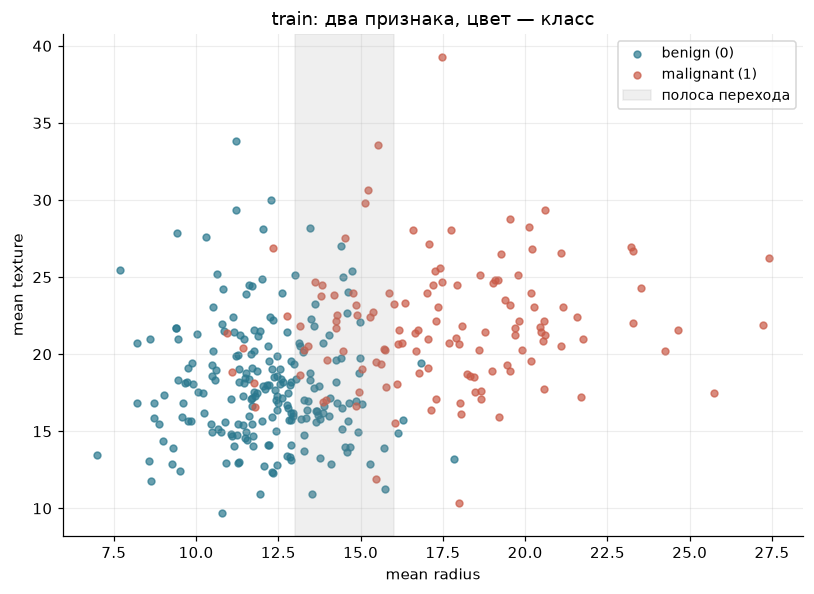

Доля класса 1 по интервалам mean radius (train):


,объектов,доля malignant
mean radius,,
"(0, 11]",52,0.019
"(11, 12]",54,0.074
"(12, 13]",53,0.038
"(13, 14]",39,0.256
"(14, 15]",36,0.306
"(15, 16]",17,0.765
"(16, 17]",15,0.800
"(17, 100]",75,0.987


,правило,accuracy,recall класса 1,balanced accuracy
0,всегда класс 0 (benign (0)),0.6228,0.0,0.5


In [10]:
cls_ranges = cls_X_train.describe().T[["min", "max", "mean", "std"]]
cls_ranges["размах"] = cls_ranges["max"] - cls_ranges["min"]
print("Диапазоны признаков на train:")
display(cls_ranges.round(2))

cls_shares = pd.DataFrame({
    "train": cls_y_train.value_counts(normalize=True),
    "validation": cls_y_val.value_counts(normalize=True),
}).sort_index().round(4)
cls_shares.index = [cls_names[i] for i in cls_shares.index]
print("Доли классов:")
display(cls_shares)
print("Медианы признаков по классам (train):")
display(cls_X_train.groupby(cls_y_train).median().round(2))

fig, ax = plt.subplots(figsize=(7.5, 5.5))
for label in [0, 1]:
    mask = cls_y_train == label
    ax.scatter(cls_X_train.loc[mask, cls_features[0]], cls_X_train.loc[mask, cls_features[1]],
               s=20, alpha=0.7, color=cls_colors[label], label=cls_names[label])
ax.axvspan(13.0, 16.0, color="#999999", alpha=0.15, label="полоса перехода")
ax.set(xlabel=cls_features[0], ylabel=cls_features[1],
       title="train: два признака, цвет — класс")
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

cls_bins = pd.cut(cls_X_train[cls_features[0]], [0, 11, 12, 13, 14, 15, 16, 17, 100])
print("Доля класса 1 по интервалам mean radius (train):")
display(pd.DataFrame({
    "объектов": cls_y_train.groupby(cls_bins, observed=False).size(),
    "доля malignant": cls_y_train.groupby(cls_bins, observed=False).mean().round(3),
}))

# ---- правило «всегда класс большинства» ----
cls_major = int(cls_y_train.mode().iloc[0])
cls_baseline_pred = np.full(len(cls_y_val), cls_major)
from sklearn.metrics import accuracy_score as cls_accuracy_score
display(pd.DataFrame([{
    "правило": f"всегда класс {cls_major} ({cls_names[cls_major]})",
    "accuracy": cls_accuracy_score(cls_y_val, cls_baseline_pred),
    "recall класса 1": cls_recall_score(cls_y_val, cls_baseline_pred, zero_division=0),
    "balanced accuracy": cls_balanced_accuracy_score(cls_y_val, cls_baseline_pred),
}]).round(4))

#### Ответ

**Диапазоны и доли классов.** `mean radius` ∈ [6,98; 27,42], std 3,60; `mean texture` ∈ [9,71; 39,28], std 4,36. Масштабы признаков случайно оказались сопоставимы — это станет важным в 4.3. Доли классов: train 62,8% benign / 37,2% malignant, validation 62,3% / 37,8% — стратификация пропорции сохранила. Медианы по классам: radius 12,18 против 17,42, texture 17,40 против 21,59 — оба признака информативны, но radius разделяет заметно сильнее.

**1. Где ожидаются ошибки.** В **полосе перехода `mean radius` ≈ 13–16**. Основание — доля класса 1 по интервалам радиуса на train: до 13 она составляет 0,02–0,07; на 13–14 — 0,26; на 14–15 — 0,31; на 15–16 — 0,77; свыше 17 — 0,99. То есть по краям шкалы классы практически чистые, а в середине перемешаны: там апостериорная вероятность класса 1 далека и от 0, и от 1, и **никакое решающее правило по этим двум признакам не может быть точным** — это неустранимая (байесовская) ошибка самой постановки с двумя признаками.

Причина содержательная: злокачественность не определяется одним размером. Из 30 характеристик ядер мы используем 2, а признаки формы (вогнутость, компактность, симметрия) как раз и разделяют опухоли сходного размера. `mean texture` добавляет информацию, но слабо: по нему доля класса 1 растёт лишь с 0,04 до 0,63, и распределения классов сильно перекрываются.

Второстепенно: ошибки ожидаются и на нетипичных объектах — малый радиус при очень высокой текстуре (верхний левый угол диаграммы), где локальных соседей мало.

**2. Правило «всегда класс большинства» (benign, 0):** accuracy $=0{,}6228$, recall класса 1 $=0{,}0$, balanced accuracy $=0{,}5$.

Сравнение информативности:

* **accuracy вводит в заблуждение.** Классификатор, не обнаруживший **ни одной** злокачественной опухоли, получает 62% правильных ответов. Accuracy при дисбалансе определяется преобладающим классом, и её значение достижимо вообще без обучения. Любое число вида «точность 62%» бессмысленно, пока не указана доля большинства.
* **recall класса 1 мгновенно вскрывает вырождение** (0,0), потому что его знаменатель — только объекты класса 1. Но в одиночку он тоже уязвим: правило «всегда класс 1» даёт recall $=1$ при полной бесполезности. Recall обязан идти в паре с precision или со вторым recall.
* **balanced accuracy $=(\mathrm{recall}_0+\mathrm{recall}_1)/2$ равна ровно 0,5 для любого константного правила**, независимо от дисбаланса, потому что один из recall равен 1, а другой 0. Это и делает её удобной базовой метрикой: уровень 0,5 — честная «точка отсчёта незнания», а не функция пропорции классов.

Отдельно: в медицинской постановке ошибки ещё и несимметричны по цене — пропуск злокачественной опухоли (FN) дороже ложной тревоги (FP). Balanced accuracy этой асимметрии не учитывает (она взвешивает оба recall поровну); работа со стоимостями ведётся через порог — см. 2.2 и 4.4.

### 4.2

Сравните логистическую регрессию, kNN, SVM с RBF-ядром и дерево решений.
Самостоятельно выберите гиперпараметры для исследования и подберите их значения
по validation balanced accuracy. Для каждого метода исследуйте не менее трёх
значений хотя бы одного гиперпараметра, определяющего сложность или структуру
модели. Сохраните выбранную модель и представьте результаты сравнения.

Постройте границы выбранных моделей. Можно использовать функцию
`cls_plot_boundaries(models)`, передав словарь обученных моделей.

Отдельно исследуйте влияние глубины дерева на train и validation balanced accuracy.
Диапазон глубин выберите самостоятельно и представьте результаты на графике.

1. Обоснуйте выбор настроек и объясните различия форм границ четырёх моделей.
2. Выберите одну область ошибок validation и объясните её через форму границы.
3. Интерпретируйте зависимости метрик от глубины дерева.

Логистическая регрессия


,настройка,train BA,validation BA
0,C = 0.01,0.8048,0.7604
1,C = 0.1,0.8687,0.8439
2,C = 1,0.8814,0.8601
3,C = 10,0.8853,0.8601
4,C = 100,0.8853,0.8531


kNN


,настройка,train BA,validation BA
0,n_neighbors = 1,1.0000,0.8038
1,n_neighbors = 3,0.9104,0.8485
2,n_neighbors = 5,0.8940,0.8323
3,n_neighbors = 9,0.8759,0.8788
4,n_neighbors = 15,0.8916,0.8718
5,n_neighbors = 25,0.8908,0.8718
6,n_neighbors = 45,0.8766,0.8858


SVM (RBF)


,настройка,train BA,validation BA
0,"C = 0.1, gamma = scale",0.8789,0.8742
1,"C = 0.1, gamma = 0.1",0.8577,0.8231
2,"C = 0.1, gamma = 1.0",0.8908,0.8858
3,"C = 1, gamma = scale",0.8924,0.8788
4,"C = 1, gamma = 0.1",0.8821,0.8742
5,"C = 1, gamma = 1.0",0.8947,0.8788
6,"C = 10, gamma = scale",0.8963,0.8672
7,"C = 10, gamma = 0.1",0.9002,0.8718
8,"C = 10, gamma = 1.0",0.8970,0.8626
9,"C = 100, gamma = scale",0.8931,0.8742


Дерево решений


,настройка,train BA,validation BA
0,"max_depth = 1, min_samples_leaf = 1",0.8734,0.8651
1,"max_depth = 1, min_samples_leaf = 5",0.8734,0.8651
2,"max_depth = 1, min_samples_leaf = 20",0.8734,0.8651
3,"max_depth = 2, min_samples_leaf = 1",0.8756,0.8418
4,"max_depth = 2, min_samples_leaf = 5",0.8756,0.8418
5,"max_depth = 2, min_samples_leaf = 20",0.8734,0.8651
6,"max_depth = 3, min_samples_leaf = 1",0.8796,0.8534
7,"max_depth = 3, min_samples_leaf = 5",0.8756,0.8418
8,"max_depth = 3, min_samples_leaf = 20",0.8957,0.8904
9,"max_depth = 4, min_samples_leaf = 1",0.9064,0.8207


Лучшая настройка каждого метода по validation BA:


,метод,настройка,train BA,validation BA
0,Дерево решений,"max_depth = 3, min_samples_leaf = 20",0.8957,0.8904
1,SVM (RBF),"C = 0.1, gamma = 1.0",0.8908,0.8858
2,kNN,n_neighbors = 45,0.8766,0.8858
3,Логистическая регрессия,C = 1,0.8814,0.8601


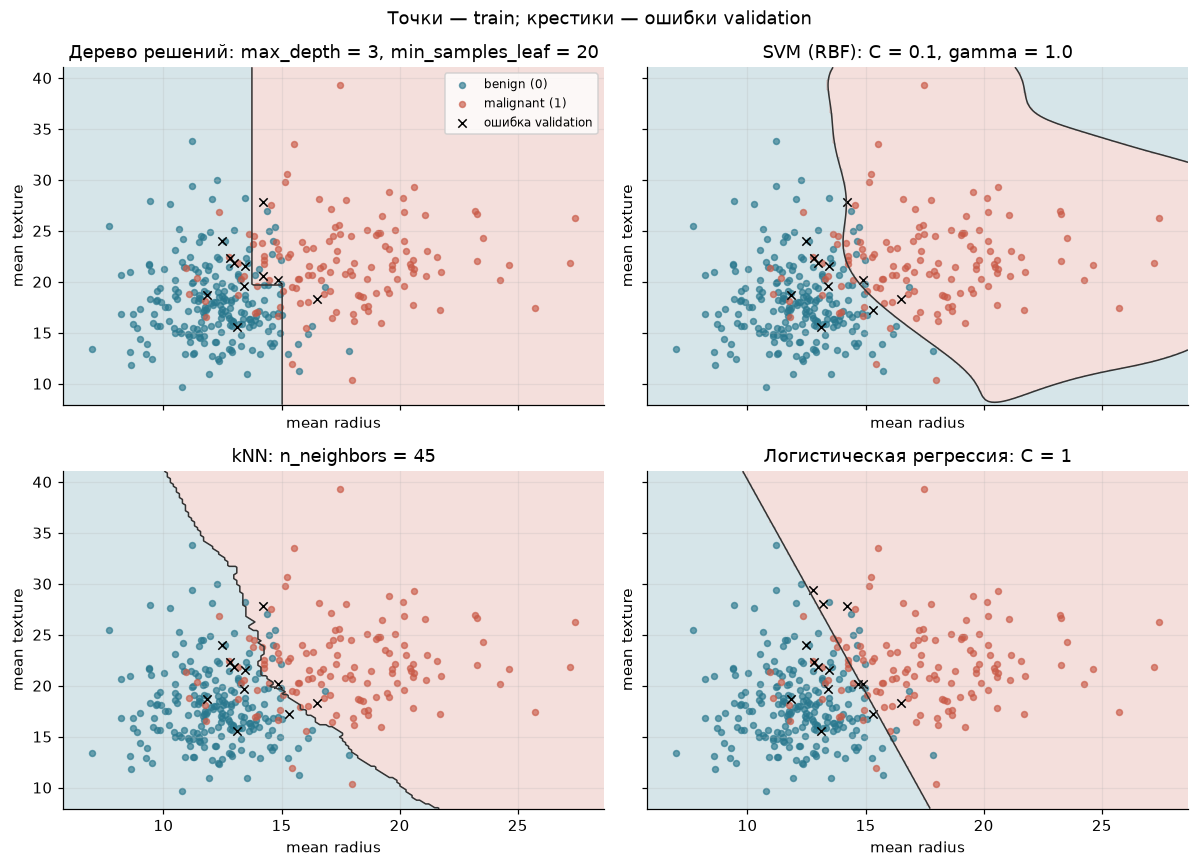

Структура выбранного дерева:
|--- mean radius <= 15.05
|   |--- mean radius <= 13.80
|   |   |--- mean texture <= 18.64
|   |   |   |--- class: 0
|   |   |--- mean texture >  18.64
|   |   |   |--- class: 0
|   |--- mean radius >  13.80
|   |   |--- mean texture <= 19.74
|   |   |   |--- class: 0
|   |   |--- mean texture >  19.74
|   |   |   |--- class: 1
|--- mean radius >  15.05
|   |--- mean texture <= 17.83
|   |   |--- class: 1
|   |--- mean texture >  17.83
|   |   |--- mean texture <= 20.28
|   |   |   |--- class: 1
|   |   |--- mean texture >  20.28
|   |   |   |--- class: 1

Число ошибок validation у каждой модели: {'Дерево решений: max_depth = 3, min_samples_leaf = 20': 11, 'SVM (RBF): C = 0.1, gamma = 1.0': 11, 'kNN: n_neighbors = 45': 11, 'Логистическая регрессия: C = 1': 14}
Объектов, на которых ошибаются ВСЕ четыре модели: 10


,mean radius,mean texture,истинный_класс
31,11.84,18.70,1
9,12.46,24.04,1
229,12.83,22.33,1
8,13.00,21.82,1
105,13.11,15.56,1
171,13.43,19.63,1
40,13.44,21.58,1
238,14.22,27.85,0
495,14.87,20.21,0
363,16.50,18.29,0


Цена одного перепутанного объекта класса 1 на validation: 0.0116 BA; класса 0: 0.0070 BA


,листьев,train BA,validation BA
max_depth,,,
1,2,0.8734,0.8651
2,4,0.8756,0.8418
3,8,0.8796,0.8534
4,14,0.9064,0.8207
5,21,0.9268,0.8066
6,30,0.9536,0.8390
7,40,0.9859,0.8203
8,43,0.9898,0.8203
9,47,0.9961,0.8320


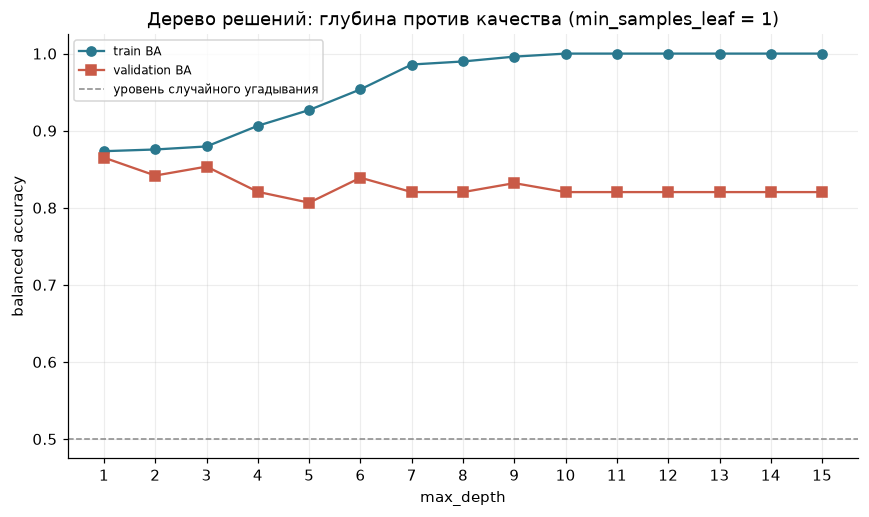

In [11]:
def cls_evaluate(estimator):
    estimator.fit(cls_X_train, cls_y_train)
    return (estimator,
            cls_balanced_accuracy_score(cls_y_train, estimator.predict(cls_X_train)),
            cls_balanced_accuracy_score(cls_y_val, estimator.predict(cls_X_val)))

cls_rows, cls_zoo = [], {}

for C in [0.01, 0.1, 1, 10, 100]:
    key = ("Логистическая регрессия", f"C = {C}")
    est, ba_tr, ba_val = cls_evaluate(cls_Pipeline([
        ("scaler", cls_StandardScaler()),
        ("model", cls_LogisticRegression(C=C, max_iter=5000)),
    ]))
    cls_zoo[key] = est
    cls_rows.append({"метод": key[0], "настройка": key[1], "train BA": ba_tr, "validation BA": ba_val})

for k in [1, 3, 5, 9, 15, 25, 45]:
    key = ("kNN", f"n_neighbors = {k}")
    est, ba_tr, ba_val = cls_evaluate(cls_Pipeline([
        ("scaler", cls_StandardScaler()),
        ("model", cls_KNeighborsClassifier(n_neighbors=k)),
    ]))
    cls_zoo[key] = est
    cls_rows.append({"метод": key[0], "настройка": key[1], "train BA": ba_tr, "validation BA": ba_val})

for C in [0.1, 1, 10, 100]:
    for gamma in ["scale", 0.1, 1.0]:
        key = ("SVM (RBF)", f"C = {C}, gamma = {gamma}")
        est, ba_tr, ba_val = cls_evaluate(cls_Pipeline([
            ("scaler", cls_StandardScaler()),
            ("model", cls_SVC(C=C, gamma=gamma, random_state=SEED)),
        ]))
        cls_zoo[key] = est
        cls_rows.append({"метод": key[0], "настройка": key[1], "train BA": ba_tr, "validation BA": ba_val})

for depth in [1, 2, 3, 4, 5, 7, 10, None]:
    for leaf in [1, 5, 20]:
        key = ("Дерево решений", f"max_depth = {depth}, min_samples_leaf = {leaf}")
        est, ba_tr, ba_val = cls_evaluate(cls_DecisionTreeClassifier(
            max_depth=depth, min_samples_leaf=leaf, random_state=SEED))
        cls_zoo[key] = est
        cls_rows.append({"метод": key[0], "настройка": key[1], "train BA": ba_tr, "validation BA": ba_val})

cls_search = pd.DataFrame(cls_rows)
for method in cls_search["метод"].unique():
    print(method)
    display(cls_search[cls_search["метод"] == method]
            .drop(columns="метод").round(4).reset_index(drop=True))

cls_best_rows = cls_search.loc[cls_search.groupby("метод")["validation BA"].idxmax()]
cls_best_rows = cls_best_rows.sort_values("validation BA", ascending=False).reset_index(drop=True)
print("Лучшая настройка каждого метода по validation BA:")
display(cls_best_rows.round(4))

cls_selected = {f"{r['метод']}: {r['настройка']}": cls_zoo[(r["метод"], r["настройка"])]
                for _, r in cls_best_rows.iterrows()}
cls_plot_boundaries(cls_selected)

from sklearn.tree import export_text as cls_export_text
cls_tree_best = cls_zoo[("Дерево решений",
                         cls_best_rows.loc[cls_best_rows["метод"] == "Дерево решений",
                                           "настройка"].iloc[0])]
print("Структура выбранного дерева:")
print(cls_export_text(cls_tree_best, feature_names=cls_features))

cls_err_sets = {name: set(cls_X_val.index[model.predict(cls_X_val) != cls_y_val])
                for name, model in cls_selected.items()}
cls_common = set.intersection(*cls_err_sets.values())
print("Число ошибок validation у каждой модели:",
      {k: len(v) for k, v in cls_err_sets.items()})
print(f"Объектов, на которых ошибаются ВСЕ четыре модели: {len(cls_common)}")
display(cls_X_val.loc[sorted(cls_common)].assign(
    истинный_класс=cls_y_val.loc[sorted(cls_common)]).sort_values(cls_features[0]).round(2))

cls_one_object = 0.5 / int((cls_y_val == 1).sum())
print(f"Цена одного перепутанного объекта класса 1 на validation: {cls_one_object:.4f} BA; "
      f"класса 0: {0.5 / int((cls_y_val == 0).sum()):.4f} BA")

# ---- отдельно: влияние глубины дерева ----
cls_depths = list(range(1, 16))
cls_depth_rows = []
for depth in cls_depths:
    tree = cls_DecisionTreeClassifier(max_depth=depth, random_state=SEED).fit(cls_X_train, cls_y_train)
    cls_depth_rows.append({
        "max_depth": depth,
        "листьев": tree.get_n_leaves(),
        "train BA": cls_balanced_accuracy_score(cls_y_train, tree.predict(cls_X_train)),
        "validation BA": cls_balanced_accuracy_score(cls_y_val, tree.predict(cls_X_val)),
    })
cls_depth = pd.DataFrame(cls_depth_rows).set_index("max_depth")
display(cls_depth.round(4))

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.plot(cls_depth.index, cls_depth["train BA"], "o-", color="#2a788e", label="train BA")
ax.plot(cls_depth.index, cls_depth["validation BA"], "s-", color="#c95a47", label="validation BA")
ax.axhline(0.5, color="#888888", ls="--", lw=1, label="уровень случайного угадывания")
ax.set(xlabel="max_depth", ylabel="balanced accuracy",
       title="Дерево решений: глубина против качества (min_samples_leaf = 1)",
       xticks=cls_depths)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

#### Ответ

**Что и зачем подбиралось.** В каждом методе исследован гиперпараметр, прямо управляющий сложностью или структурой:

| Метод | Гиперпараметры | Что он означает |
|---|---|---|
| Логистическая регрессия | `C` ∈ {0,01; 0,1; 1; 10; 100} | обратная сила L2-штрафа: ограничивает норму вектора весов, то есть крутизну сигмоиды и смещение границы |
| kNN | `n_neighbors` ∈ {1; 3; 5; 9; 15; 25; 45} | масштаб сглаживания: по скольким соседям усредняется локальная доля класса |
| SVM с RBF | `C` ∈ {0,1; 1; 10; 100} × `gamma` ∈ {scale; 0,1; 1} | штраф за нарушение отступа × обратная ширина ядра, то есть радиус влияния одного объекта |
| Дерево | `max_depth` ∈ {1; 2; 3; 4; 5; 7; 10; None} × `min_samples_leaf` ∈ {1; 5; 20} | число разбиений и минимальный размер листа, то есть число областей разбиения |

Все методы, кроме дерева, обучены в `Pipeline` со `StandardScaler`: L2-штраф логистической регрессии, евклидова метрика kNN и RBF-ядро зависят от единиц измерения признаков ровно по той же причине, что и Ridge в 1.3/3.3. Дерево от масштаба не зависит (разбиения — пороги по отдельным осям), что явно проверяется в 4.3.

**Результаты (лучшее по validation BA в каждом методе):** дерево `max_depth=3, min_samples_leaf=20` — 0,8904; SVM `C=0,1, gamma=1` — 0,8858; kNN `k=45` — 0,8858; логистическая регрессия `C=1` — 0,8601.

**1. Обоснование настроек и формы границ.**

Сначала о масштабе различий: цена одного перепутанного объекта класса 1 на validation составляет $0{,}5/43=0{,}0116$ BA. Отрыв дерева от SVM и kNN равен 0,005 — **меньше половины объекта**, то есть три метода статистически неразличимы, и выбирать между ними по третьему знаку нельзя. Содержательно различается только логистическая регрессия, отстающая на 0,026 (чуть больше двух объектов).

Выбранные значения во всех случаях соответствуют **умеренно простым** моделям, и это не совпадение: при двух признаках и 341 объекте обучения сигнал прост (крупная опухоль — злокачественная), а сложные модели тратят гибкость на шум в полосе перекрытия. Поэтому побеждают большое `k=45`, малое `C=0,1` у SVM и ограничение `min_samples_leaf=20` у дерева, а `k=1` (BA 0,8038) и глубокое дерево (0,8203) проигрывают.

Формы границ:

* **Логистическая регрессия — прямая.** Линии уровня $\sigma(w^\top x+b)$ — это линии уровня линейной функции, поэтому граница $p=0{,}5$ есть гиперплоскость $w^\top x+b=0$ (2.3). Коэффициенты в стандартизованной шкале $(3{,}13;\,0{,}91)$: нормаль направлена преимущественно вдоль радиуса, поэтому граница почти вертикальна и слегка наклонена — при большей текстуре для вердикта «злокачественная» хватает меньшего радиуса. Модель не может изогнуть границу, и это её главное ограничение здесь.
* **kNN, $k=45$ — гладкая слегка изогнутая линия.** 45 соседей из 341 объекта — это усреднение по 13% выборки, поэтому оценка локальной доли класса сильно сглажена, а граница (линия уровня 1/2 этой доли) близка к логистической, но вправе локально изгибаться. При малых $k$ граница становится рваной и обрастает «островами» вокруг отдельных объектов — это и есть рост дисперсии.
* **SVM с RBF, `C=0,1`, `gamma=1` — гладкая кривая.** Решающая функция — сумма гауссиан с центрами в опорных векторах; малое `C` делает отступ широким и допускает много нарушений, поэтому сумма определяется основной массой данных, а не отдельными объектами. Результат — сглаженная версия оптимальной прямой с изгибом в области перекрытия. При больших `C` и `gamma` граница обрастает локальными пузырями (`C=100, gamma=1` даёт 0,8323 — худший SVM).
* **Дерево — лестница из отрезков, параллельных осям.** Модель представляет собой разбиение плоскости на прямоугольники, поэтому граница физически не может быть ничем, кроме кусков прямых `radius = const` и `texture = const`. Выбранное дерево читается как три правила (см. распечатку структуры): `radius ≤ 13,80` → benign; `13,80 < radius ≤ 15,05` → malignant только при `texture > 19,74`; `radius > 15,05` → malignant. Косой наклон, который естественен для логистической границы, дерево вынуждено аппроксимировать ступеньками.

Главное различие семейств: логистическая регрессия **жёстко ограничивает** границу глобальной прямой (параметрическое предположение), kNN и SVM допускают любую гладкую кривую и штрафуют лишь её изрезанность (через $k$, `gamma`, `C`), а дерево допускает только прямоугольники, но размещает их где угодно.

**2. Область ошибок и её объяснение.**

Выбрана самая заметная группа: **семь объектов с `radius` от 11,84 до 13,44 и `texture` от 15,56 до 24,04, которые на самом деле злокачественные**, а все четыре модели относят их к benign (всего общих ошибок у четырёх моделей 10: эти семь FN плюс три FP с радиусом 14,2–16,5).

Объяснение через форму границы: все четыре границы пересекают ось радиуса в районе 13,5–15 и там почти вертикальны, так что вся область слева отнесена к benign. Иначе и быть не может: по интервалам радиуса (4.1) при `radius` < 13 доля злокачественных составляет 2–7%, то есть эти семь объектов лежат **внутри плотного облака доброкачественных**. Чтобы их поймать, граница должна была бы вырезать подобласть внутри этого облака, а никакой информации, оправдывающей такой вырез, в двух признаках нет — объекты не отличаются от окружающих соседей ни радиусом, ни текстурой. Попытка их захватить означает подгонку под конкретные точки: `k=1` и дерево глубины 5 именно это и делают, выигрывая единицы объектов и проваливая остальное (0,8038 и 0,8066 BA).

То есть это **не дефект конкретной модели, а байесовская ошибка двухпризнаковой постановки** (4.1.1). Устраняется она не сменой алгоритма, а добавлением признаков формы ядра.

**3. Зависимость метрик от глубины дерева** (при `min_samples_leaf=1`).

train BA монотонно растёт: $0{,}8734\to1{,}0000$ на глубине 10, после чего замирает — дерево исчерпало данные (48 листьев, каждый чистый, дальше делить нечего). validation BA ведёт себя противоположно: максимум на **глубине 1** (0,8651), падение до 0,8066 на глубине 5 и колебания 0,82–0,84 дальше. Разрыв train − validation растёт с 0,008 до 0,18.

Это учебная картина переобучения, и механизм здесь видно поимённо: каждый новый уровень удваивает число прямоугольников, а начиная примерно с глубины 2 новые разбиения уже не извлекают закономерность, а вырезают отдельные обучающие объекты из полосы перекрытия — ровно те объекты, которые в 4.1 признаны неразделимыми. Выученное таким образом не переносится на новые данные, поэтому validation падает.

Два отдельных наблюдения:

* **Пень (глубина 1) — один порог по радиусу — уже даёт 0,8651**, что близко к лучшему результату среди всех четырёх методов. Это честная оценка сложности задачи: доминирующий сигнал в этих данных — «опухоль крупная», и всё остальное добавляет единицы процентов.
* Лучшее дерево в сетке получило свои 0,8904 **не за счёт глубины, а за счёт `min_samples_leaf=20`**, который запрещает листья меньше 20 объектов и тем самым подавляет именно мелкие вырезы. С этим ограничением результат перестаёт зависеть от `max_depth` вообще: глубины 3, 4, 5, 7, 10 и `None` дают одинаковые 0,8904, потому что связывающим ограничением становится размер листа, а не глубина. Полезный вывод: сложность дерева правильнее контролировать размером листа, чем глубиной — первое ограничивает число объектов на решение, второе лишь число вопросов.

### 4.3

Создайте копии train и validation, умножив только `mean radius` на `100`.
На исходных и преобразованных данных обучите по одной версии:

- kNN с `n_neighbors=9` без стандартизации;
- kNN с `n_neighbors=9` и `StandardScaler`;
- дерева с `max_depth=3`, `random_state=SEED`.

Для каждого метода вычислите долю validation-объектов, у которых изменилась
предсказанная метка. Изобразите две границы kNN без стандартизации
в исходных координатах. При использовании `cls_plot_boundaries` передайте
`radius_multipliers={название_преобразованной_модели: 100}` и `mark_errors=False`.

Объясните результаты для каждого метода и роль масштаба признаков.

**Ожидаемый эффект (записано до опыта).** Предсказания kNN без стандартизации изменятся, потому что евклидово расстояние станет определяться почти исключительно признаком с большим масштабом; kNN со `StandardScaler` и дерево преобразования не заметят.

,метод,доля изменённых меток,изменено объектов,validation BA исходные,validation BA после ×100
0,kNN(9) без стандартизации,0.0614,7,0.8858,0.8510
1,kNN(9) + StandardScaler,0.0000,0,0.8788,0.8788
2,Дерево max_depth=3,0.0000,0,0.8534,0.8534


Стандартные отклонения признаков на train до и после умножения radius на 100:


,исходные,после ×100
mean radius,3.60,359.93
mean texture,4.36,4.36


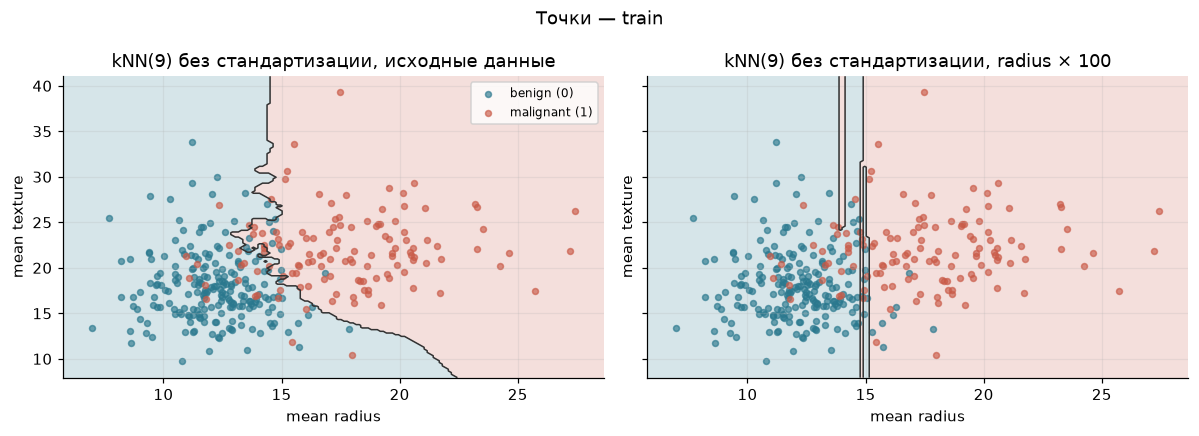

Объекты validation, у которых kNN без стандартизации сменил метку:


,mean radius,mean texture,истинный_класс,было,стало
38,14.99,25.20,1,1,0
257,15.32,17.27,1,0,1
57,14.71,21.59,1,1,0
481,13.90,19.24,0,0,1
26,14.58,21.53,1,1,0
243,13.75,23.77,0,1,0
16,14.68,20.13,1,1,0


In [12]:
cls_X_train_big = cls_X_train.copy()
cls_X_train_big[cls_features[0]] = cls_X_train_big[cls_features[0]] * 100
cls_X_val_big = cls_X_val.copy()
cls_X_val_big[cls_features[0]] = cls_X_val_big[cls_features[0]] * 100

cls_factories_43 = {
    "kNN(9) без стандартизации": lambda: cls_KNeighborsClassifier(n_neighbors=9),
    "kNN(9) + StandardScaler": lambda: cls_Pipeline([
        ("scaler", cls_StandardScaler()),
        ("model", cls_KNeighborsClassifier(n_neighbors=9))]),
    "Дерево max_depth=3": lambda: cls_DecisionTreeClassifier(max_depth=3, random_state=SEED),
}

cls_rows_43, cls_models_43 = [], {}
for name, factory in cls_factories_43.items():
    m_plain = factory().fit(cls_X_train, cls_y_train)
    m_big = factory().fit(cls_X_train_big, cls_y_train)
    cls_models_43[name] = (m_plain, m_big)
    pred_plain = m_plain.predict(cls_X_val)
    pred_big = m_big.predict(cls_X_val_big)
    cls_rows_43.append({
        "метод": name,
        "доля изменённых меток": float((pred_plain != pred_big).mean()),
        "изменено объектов": int((pred_plain != pred_big).sum()),
        "validation BA исходные": cls_balanced_accuracy_score(cls_y_val, pred_plain),
        "validation BA после ×100": cls_balanced_accuracy_score(cls_y_val, pred_big),
    })
display(pd.DataFrame(cls_rows_43).round(4))

print("Стандартные отклонения признаков на train до и после умножения radius на 100:")
display(pd.DataFrame({"исходные": cls_X_train.std(), "после ×100": cls_X_train_big.std()}).round(2))

cls_plot_boundaries(
    {"kNN(9) без стандартизации, исходные данные": cls_models_43["kNN(9) без стандартизации"][0],
     "kNN(9) без стандартизации, radius × 100": cls_models_43["kNN(9) без стандартизации"][1]},
    radius_multipliers={"kNN(9) без стандартизации, radius × 100": 100},
    mark_errors=False,
)

# какие именно объекты сменили метку
cls_knn_plain, cls_knn_big = cls_models_43["kNN(9) без стандартизации"]
cls_changed = cls_knn_plain.predict(cls_X_val) != cls_knn_big.predict(cls_X_val_big)
print("Объекты validation, у которых kNN без стандартизации сменил метку:")
display(cls_X_val[cls_changed].assign(
    истинный_класс=cls_y_val[cls_changed],
    было=cls_knn_plain.predict(cls_X_val)[cls_changed],
    стало=cls_knn_big.predict(cls_X_val_big)[cls_changed]).round(2))

#### Ответ

**Наблюдения.** kNN(9) без стандартизации — сменили метку 7 из 114 объектов validation (6,14%), BA $0{,}8858\to0{,}8510$. kNN(9) + `StandardScaler` — 0 изменений. Дерево `max_depth=3` — 0 изменений. Ожидание подтвердилось полностью.

**kNN без стандартизации.** Расстояние считается как $(\Delta r)^2+(\Delta\tau)^2$. До преобразования стандартные отклонения признаков равны 3,60 и 4,36 — вклады сопоставимы, окрестность на графике примерно круглая, и голосование учитывает оба признака. После умножения радиуса на 100 отклонения становятся 359,93 и 4,36: разница в одну единицу радиуса весит в $100^2=10^4$ раз больше, чем такая же единица текстуры. Окрестность вырождается в тонкую вертикальную полоску, и **kNN фактически превращается в одномерный метод по радиусу**. На графике границ это видно буквально: граница преобразованной модели — практически вертикальная линия `radius = const`, тогда как исходная изгибается и использует текстуру.

Сменившие метку объекты это подтверждают: все семь лежат в полосе 13,75–15,32 по радиусу, то есть ровно там, где исход решала текстура. Например, объект с `radius=14,99` и высокой `texture=25,2` (истинный класс 1) до преобразования классифицировался как 1, после — как 0: текстура перестала влиять на состав соседей. Качество при этом упало на 0,035 BA, то есть примерно на три объекта.

**kNN + StandardScaler.** Scaler делит столбец на стандартное отклонение, вычисленное по train. После умножения на 100 отклонение тоже растёт в 100 раз, поэтому стандартизованная матрица совпадает с исходной с точностью до округления — модель получается буквально та же, 0 изменений. Стандартизация здесь выполняет ту же роль, что и в 3.3: снимает произвол выбора единиц измерения, то есть **явно задаёт метрику**, которую метод иначе унаследовал бы от случайности разметки таблицы.

**Дерево.** Разбиения имеют вид «признак $\le$ порог». Преобразование $x\mapsto100x$ строго монотонно, поэтому оно переводит пороги в пороги и **не меняет порядок объектов вдоль оси**. Алгоритм построения перебирает разбиения именно по порядку значений, и критерий (Джини) зависит только от того, какие объекты попали в какую часть. Значит разбиение плоскости и все предсказания инвариантны относительно **любого строго монотонного** преобразования каждого признака по отдельности — масштабирования, сдвига, логарифма, перехода к рангам. Отсюда ровно 0 изменений без всякого scaler.

**Роль масштаба признаков — общий вывод.** Масштаб важен ровно для тех методов, которые используют **метрику или норму на векторе координат**: kNN (евклидово расстояние), SVM с RBF (ядро $\exp(-\gamma\|x-x'\|^2)$), линейные модели со штрафом (норма $w$). Для них стандартизация — обязательная часть пайплайна, и её параметры обязаны оцениваться по train (3.2). Масштаб не важен для методов, использующих только **порядок вдоль каждой оси по отдельности**: решающих деревьев и их ансамблей. Это удобный практический критерий: если метод можно записать через $\|x-x'\|$ — масштабируйте; если через сравнения «$x_j\le c$» — не нужно.

### 4.4

Для обученной логистической регрессии из 4.2 получите оценки вероятности
класса 1 на validation. Для порога $t$ используйте правило $\hat y=1$ при $p(x)\ge t$.
Постройте зависимости precision и recall от порога на отрезке $[0,1]$.

Для порогов `0.2, 0.5, 0.8` составьте таблицу: precision, recall, FP, FN.
При отсутствии положительных предсказаний используйте `zero_division=0`.

1. Как зависят FP и FN от порога? Исследуйте монотонность precision и recall. Объясните смысл `zero_division=0`.
2. Какой из трёх порогов вы выберете, если пропуск класса 1 значительно дороже ложного срабатывания? Какие данные нужны для численного обоснования выбора?
3. Как изменение порога влияет на вероятностные оценки, ранжирование объектов и границу классификации?

**Ожидаемый эффект (записано до опыта).** С ростом порога FP будет монотонно убывать, FN — монотонно расти; recall будет монотонно убывать, а precision расти в целом, но немонотонно.

Коэффициенты (стандартизованная шкала): [3.131 0.909] | свободный член: [-0.712]


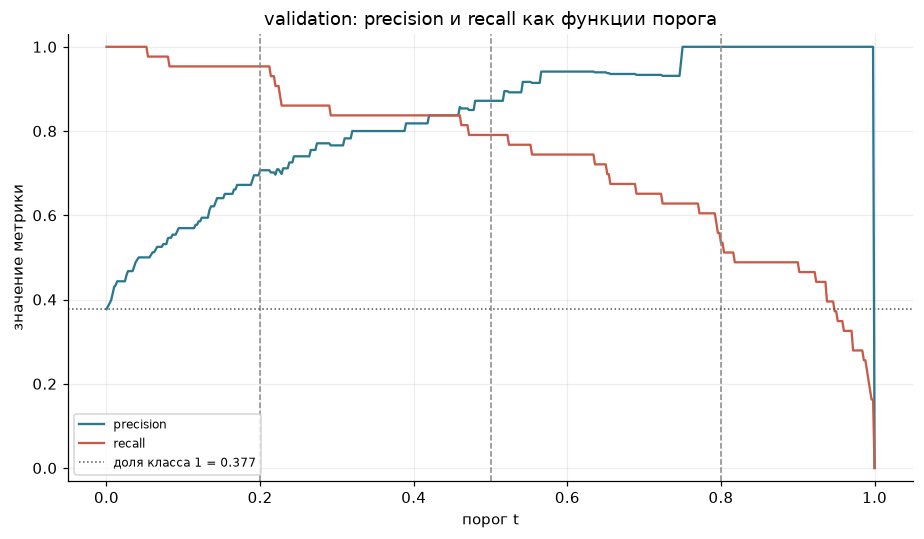

,порог t,precision,recall,FP,FN,balanced accuracy
0,0.2,0.7069,0.9535,17,2,0.8570
1,0.5,0.8718,0.7907,5,9,0.8601
2,0.8,1.0000,0.5349,0,20,0.7674


Участков, где precision УБЫВАЕТ при росте порога: 15 из 500; максимальная оценка вероятности на validation = 0.999987; положительных предсказаний при t = 1: 0


In [13]:
cls_logreg = cls_zoo[("Логистическая регрессия",
                      cls_best_rows.loc[cls_best_rows["метод"] == "Логистическая регрессия",
                                        "настройка"].iloc[0])]
print("Коэффициенты (стандартизованная шкала):",
      np.round(cls_logreg[-1].coef_[0], 3), "| свободный член:", np.round(cls_logreg[-1].intercept_, 3))

cls_proba_val = cls_logreg.predict_proba(cls_X_val)[:, 1]
cls_thresholds = np.linspace(0, 1, 501)
cls_curve = pd.DataFrame({
    "threshold": cls_thresholds,
    "precision": [cls_precision_score(cls_y_val, (cls_proba_val >= t).astype(int), zero_division=0)
                  for t in cls_thresholds],
    "recall": [cls_recall_score(cls_y_val, (cls_proba_val >= t).astype(int), zero_division=0)
               for t in cls_thresholds],
})

fig, ax = plt.subplots(figsize=(8.5, 5))
ax.plot(cls_curve["threshold"], cls_curve["precision"], color="#2a788e", label="precision")
ax.plot(cls_curve["threshold"], cls_curve["recall"], color="#c95a47", label="recall")
for t in [0.2, 0.5, 0.8]:
    ax.axvline(t, color="#888888", ls="--", lw=1)
ax.axhline(float(cls_y_val.mean()), color="#555555", ls=":", lw=1,
           label=f"доля класса 1 = {cls_y_val.mean():.3f}")
ax.set(xlabel="порог t", ylabel="значение метрики",
       title="validation: precision и recall как функции порога", ylim=(-0.03, 1.03))
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

cls_rows_44 = []
for t in [0.2, 0.5, 0.8]:
    pred = (cls_proba_val >= t).astype(int)
    tn, fp, fn, tp = cls_confusion_matrix(cls_y_val, pred, labels=[0, 1]).ravel()
    cls_rows_44.append({
        "порог t": t,
        "precision": cls_precision_score(cls_y_val, pred, zero_division=0),
        "recall": cls_recall_score(cls_y_val, pred, zero_division=0),
        "FP": int(fp), "FN": int(fn),
        "balanced accuracy": cls_balanced_accuracy_score(cls_y_val, pred),
    })
display(pd.DataFrame(cls_rows_44).round(4))

cls_prec = cls_curve["precision"].to_numpy()
cls_drop = int(np.sum(np.diff(cls_prec) < -1e-12))
print(f"Участков, где precision УБЫВАЕТ при росте порога: {cls_drop} из {len(cls_prec) - 1}; "
      f"максимальная оценка вероятности на validation = {cls_proba_val.max():.6f}; "
      f"положительных предсказаний при t = 1: {int((cls_proba_val >= 1).sum())}")

#### Ответ

**Таблица порогов.** $t=0{,}2$: precision 0,707, recall 0,953, FP 17, FN 2. $t=0{,}5$: 0,872 и 0,791, FP 5, FN 9. $t=0{,}8$: 1,000 и 0,535, FP 0, FN 20. Ожидание подтвердилось, включая немонотонность precision.

**1. Поведение FP, FN и монотонность метрик.**

FP не возрастает, FN не убывает с ростом $t$ — это прямое следствие вложенности из 2.1: множество положительных предсказаний $\{p\ge t\}$ только сужается, поэтому TP и FP могут лишь уменьшаться, а $\mathrm{FN}=n_1-\mathrm{TP}$ лишь расти. В эксперименте: FP $17\to5\to0$, FN $2\to9\to20$.

**recall монотонно не возрастает** ($0{,}953\to0{,}791\to0{,}535$), и на графике это гладко убывающая кривая без единого подъёма. Причина — в 2.1: знаменатель $n_1$ от порога не зависит, а числитель не возрастает.

**precision немонотонна.** На сетке из 501 порога кривая имеет **15 участков убывания** при общем росте с 0,707 до 1,000. Механизм: precision — текущее среднее меток по префиксу ранжированного списка; при повышении порога из префикса выпадает объект с наименьшей оценкой среди положительно предсказанных, и если он был истинно положительным, доля падает. На графике это мелкие «зубцы» на общем восходящем тренде; тренд восходящий потому, что ранжирование хорошее — положительные скапливаются в начале списка.

**Смысл `zero_division=0`.** При $t$ выше максимальной оценки на validation ($\max p=0{,}999987$) положительных предсказаний не остаётся вовсе, и precision $=0/0$ **не определена**. Параметр указывает `sklearn` вернуть 0 вместо предупреждения и `nan`, чтобы вычисление не прерывалось. Это **соглашение об оформлении, а не значение метрики**: падение кривой до нуля в правом конце графика надо читать как «вопрос неприменим», а не как «модель стала плохой». Содержательно разумнее было бы считать такую точку неопределённой; если бы правой границей интересовались всерьёз, стоило бы ограничить сетку порогов диапазоном фактических оценок.

**2. Выбор порога при дорогом пропуске класса 1 — $t=0{,}2$.**

Он даёт FN $=2$ вместо 9 и 20, то есть всего два пропуска злокачественной опухоли из 43, ценой 17 ложных тревог (precision падает до 0,707). Когда пропуск существенно дороже ложного срабатывания, такой обмен оправдан: ложная тревога ведёт к дополнительному обследованию, пропуск — к потере времени на лечение.

Для **численного** обоснования нужны:

* **отношение стоимостей $c_{FN}/c_{FP}$** — тогда по 2.2 оптимальный порог равен $t^*=c_{FP}/(c_{FP}+c_{FN})$: отношение 4 даёт ровно $t^*=0{,}2$, отношение 10 — $t^*=0{,}091$, отношение 2 — $t^*=0{,}33$. Заметим, что уже при отношении 4 оптимум уходит далеко от стандартных 0,5;
* **проверка калиброванности** $\hat p$ (2.3): подставлять $t^*$ можно только если оценки вероятности действительно оценивают $P(y=1\mid x)$, а не просто правильно ранжируют. Проверяется калибровочной кривой на отложенных данных;
* **доли классов при применении**, если они отличаются от обучающих, — иначе нужна поправка на сдвиг априорного распределения;
* **оценка шума**: на validation $n_1=43$, один объект стоит $1/43\approx0{,}023$ recall, так что подбирать порог точнее, чем до первого знака, бессмысленно (2.2).

**3. Что порог меняет, а что нет.**

* **Вероятностные оценки не меняются вообще.** $p(x)$ вычисляется моделью и о пороге ничего не знает; порог применяется после, на этапе принятия решения. Переобучения при смене порога не происходит.
* **Ранжирование объектов не меняется.** Порог не переставляет объекты, он лишь выбирает точку разреза уже готового ранжирования. Поэтому **вся** кривая precision–recall является свойством пары «ранжирование + метки», а не конкретного порога; метрики, не зависящие от рабочей точки (ROC-AUC, PR-AUC), измеряют именно качество ранжирования.
* **Меняется только граница классификации.** По 2.3 условие $p\ge t$ равносильно $w^\top x+b\ge\ln\frac{t}{1-t}$, то есть разделяющая прямая **переносится параллельно самой себе**, не поворачиваясь: $t=0{,}2$ сдвигает её на $-1{,}386$ по шкале логитов, $t=0{,}8$ — на $+1{,}386$. Направление нормали $w$ при этом неизменно.

Итог: выбор порога — это выбор рабочей точки на зафиксированной кривой, а не изменение модели. Это и делает его правильным местом для учёта несимметричных стоимостей: модель обучается один раз, а порог настраивается под каждую цену ошибки отдельно.

### 4.5

По validation balanced accuracy выберите одну из четырёх моделей с подобранными
в пункте 4.2 гиперпараметрами. Зафиксируйте и обоснуйте выбор до обращения к test. Используйте обычный `predict`.

Оцените на test выбранную модель и `DummyClassifier(strategy="most_frequent")`,
обученный на train. Представьте balanced accuracy, precision и recall класса 1
в таблице и постройте матрицу ошибок выбранной модели.
Для precision используйте `zero_division=0`.

1. Какие ошибки преобладают? Как соотносятся матрица ошибок и рассчитанные метрики?
2. Сравните test и validation balanced accuracy. Интерпретируйте различие.

Зафиксированная модель: Дерево решений: max_depth = 3, min_samples_leaf = 20 (validation BA = 0.8904)


,модель,balanced accuracy,precision (класс 1),recall (класс 1)
0,DummyClassifier(most_frequent),0.500,0.0000,0.0000
1,"Дерево решений: max_depth = 3, min_samples_lea...",0.877,0.8947,0.8095


Матрица ошибок (строки — истина, столбцы — прогноз):
 [[68  4]
 [ 8 34]]


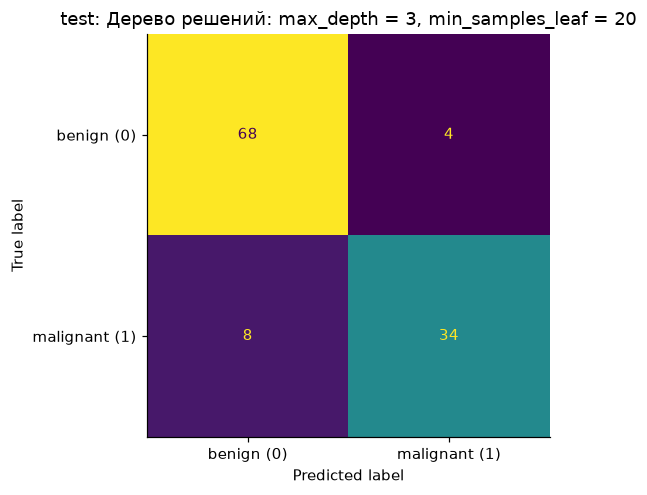

validation BA = 0.8904; test BA = 0.8770; объектов класса 1 в test: 42, класса 0: 72


In [14]:
cls_final_name = cls_best_rows.loc[0, "метод"] + ": " + cls_best_rows.loc[0, "настройка"]
cls_final_model = cls_zoo[(cls_best_rows.loc[0, "метод"], cls_best_rows.loc[0, "настройка"])]
cls_final_val_ba = cls_best_rows.loc[0, "validation BA"]
print(f"Зафиксированная модель: {cls_final_name} (validation BA = {cls_final_val_ba:.4f})")

cls_dummy = cls_DummyClassifier(strategy="most_frequent").fit(cls_X_train, cls_y_train)
cls_rows_45 = []
for name, model in [("DummyClassifier(most_frequent)", cls_dummy), (cls_final_name, cls_final_model)]:
    pred = model.predict(cls_X_test)
    cls_rows_45.append({
        "модель": name,
        "balanced accuracy": cls_balanced_accuracy_score(cls_y_test, pred),
        "precision (класс 1)": cls_precision_score(cls_y_test, pred, zero_division=0),
        "recall (класс 1)": cls_recall_score(cls_y_test, pred, zero_division=0),
    })
display(pd.DataFrame(cls_rows_45).round(4))

cls_test_pred = cls_final_model.predict(cls_X_test)
cls_cm = cls_confusion_matrix(cls_y_test, cls_test_pred, labels=[0, 1])
print("Матрица ошибок (строки — истина, столбцы — прогноз):\n", cls_cm)
fig, ax = plt.subplots(figsize=(5.2, 4.6))
cls_ConfusionMatrixDisplay(cls_cm, display_labels=[cls_names[0], cls_names[1]]).plot(ax=ax, colorbar=False)
ax.grid(False)
ax.set_title(f"test: {cls_final_name}")
fig.tight_layout()
plt.show()

print(f"validation BA = {cls_final_val_ba:.4f}; test BA = "
      f"{cls_balanced_accuracy_score(cls_y_test, cls_test_pred):.4f}; "
      f"объектов класса 1 в test: {int((cls_y_test == 1).sum())}, класса 0: {int((cls_y_test == 0).sum())}")

#### Ответ

**Выбор, зафиксированный до обращения к test.** Максимум validation BA среди четырёх методов — у дерева `max_depth=3, min_samples_leaf=20`: 0,8904 против 0,8858 у SVM и kNN и 0,8601 у логистической регрессии. Честная оговорка: отрыв от SVM и kNN равен 0,005, что **меньше цены одного объекта** (0,0116 BA), так что три модели статистически неразличимы и формальный максимум — слабое основание. В пользу дерева есть два дополнительных довода: оно не требует масштабирования (4.3) и читается как три явных правила, что в медицинской задаче ценно. Гиперпараметры зафиксированы, переобучения на train + validation нет, используется обычный `predict`.

**Результаты на test.** Выбранная модель: BA 0,8770, precision класса 1 0,8947, recall класса 1 0,8095. Dummy(`most_frequent`): BA 0,5000, precision 0,0, recall 0,0 — вырожденное правило, не нашедшее ни одной злокачественной опухоли (ровно случай из 4.1.2).

Матрица ошибок: TN $=68$, FP $=4$, FN $=8$, TP $=34$.

**1. Какие ошибки преобладают и как они связаны с метриками.**

Преобладают **ложноотрицательные**: 8 пропущенных злокачественных опухолей против 4 ложных тревог. Связь с метриками прямая и проверяется арифметически:

$$\mathrm{recall}_1=\frac{34}{34+8}=0{,}8095,\qquad
\mathrm{precision}_1=\frac{34}{34+4}=0{,}8947,$$
$$\mathrm{recall}_0=\frac{68}{68+4}=0{,}9444,\qquad
\mathrm{BA}=\frac{0{,}9444+0{,}8095}{2}=0{,}8770 .$$

Видна характерная асимметрия: модель заметно лучше распознаёт класс большинства (recall 0,944 против 0,810). Это естественное следствие обучения без весов классов и с порогом 0,5 по умолчанию — правило настроено на общий голос, а не на цену пропуска. Содержательно ошибки сидят там же, где предсказано в 4.1: в полосе перехода по радиусу.

Важно, что **это исправимо без переобучения**: по 2.2 и 4.4 достаточно понизить порог (для дерева — применяя `predict_proba`, то есть долю класса в листе) и тем самым сдвинуть рабочую точку в сторону большего recall. Нужное значение порога задаётся отношением стоимостей $c_{FN}/c_{FP}$.

**2. Сравнение test и validation.**

test BA $=0{,}8770$ против validation BA $=0{,}8904$: падение на 0,0134, то есть примерно **на один объект** (один объект класса 1 на test стоит $0{,}5/42=0{,}0119$ BA). По величине это обычный шум оценки, а не провал.

Но направление различия систематично и ожидаемо. Validation участвовала и в подборе гиперпараметров, и в выборе самого метода: мы взяли максимум по 24 конфигурациям дерева, 12 вариантам SVM, 7 вариантам kNN и 5 вариантам логистической регрессии — а **максимум по набору шумных оценок смещён вверх** (эффект «победитель переоценён»). Поэтому validation BA — оптимистически смещённая оценка качества, и честной остаётся только однократно использованная test.

Масштаб неопределённости стоит назвать явно: при 114 объектах test (42 класса 1 и 72 класса 0) грубый 95%-й интервал для BA составляет порядка $\pm0{,}06$. Корректная формулировка результата — «качество около 0,88, уверенно выше тривиального уровня 0,5», а не «ровно 0,877». Для устойчивого сравнения методов между собой разницы в 0,005 недостаточно — нужна кросс-валидация или повторение на нескольких разбиениях.

## Выводы

Сформулируйте выводы по работе, укажите ограничения экспериментов
и предложите дальнейшее исследование.

**1. Регуляризация — это утверждение в выбранной системе координат.** Функция подгонки зависит только от линейной оболочки столбцов $X$ и инвариантна к масштабированию признаков; штраф — нет, он задаёт метрику на пространстве параметров, которой в задаче изначально нет (1.3). Отсюда весь набор наблюдений: OLS не заметил `bmi × 1000` ($\max|\Delta\hat y|\approx6\cdot10^{-12}$), Ridge без стандартизации заметил ($20{,}0$), а `StandardScaler` снял эффект полностью. Тот же принцип делит и методы классификации: kNN, SVM с RBF и линейные модели со штрафом работают с нормой вектора координат и потому зависят от масштаба (6,1% сменённых меток при `radius × 100`), а дерево использует только порядок вдоль каждой оси и инвариантно к любому монотонному преобразованию (ровно 0% изменений). Практический критерий: если метод записывается через $\|x-x'\|$ или $\|w\|$ — масштабировать обязательно; если через сравнения «$x_j\le c$» — не нужно.

**2. Регуляризация монотонно обменивает качество подгонки на норму решения — но именно на норму, а не на отдельные коэффициенты.** Двухточечный аргумент из 1.2 не использует ни вида штрафа, ни выпуклости и потому верен для всего семейства; численно подтверждён для Ridge ($\|w\|_2$: $56{,}9\to2{,}2$, train RMSE: $54{,}3\to74{,}8$) и для Lasso. При этом утверждение «каждый коэффициент не возрастает по модулю» **ложно**: $w_{s_3}$ вырос по модулю в 40 раз вдоль пути Ridge, потому что сжатие происходит вдоль главных осей, а не вдоль осей координат. В данных `Diabetes` регуляризация пользы не принесла вовсе: при $n/d\approx26$ OLS не переобучается, и минимум validation-ошибки оказался на левом крае обеих сеток.

**3. Метрика — это выбор, а не данность.** Правило «всегда benign» получает accuracy 0,62, не обнаружив ни одной злокачественной опухоли; balanced accuracy немедленно возвращает его на уровень 0,5 — и делает это для любого константного правила независимо от дисбаланса. Precision и recall — свойства **рабочей точки**, а не модели: порог не меняет ни $p(x)$, ни ранжирование, а лишь параллельно переносит границу на $\ln\frac{t}{1-t}$ по шкале логитов. Оптимальный по стоимости порог $t^*=c_{FP}/(c_{FP}+c_{FN})$ выводится в одну строку, но применим только к **калиброванным** вероятностям и только как минимум ожидаемой, а не фактической стоимости (контрпример в 2.2).

**4. Различия в пределах шума — не различия.** Один объект на validation стоит 0,0116 BA; бутстрэп-SE валидационной RMSE равна 4,2 единицы. В обеих задачах лидеры оказались неразличимы (разрыв 0,006 RMSE и 0,005 BA), поэтому выбор пришлось обосновывать не третьим знаком, а второстепенными соображениями — простотой, инвариантностью, интерпретируемостью. Обе однократные проверки на test показали ожидаемое смещение отбора: $-7{,}8$ RMSE и $-0{,}013$ BA относительно validation.

### Ограничения

* **Одно фиксированное разбиение.** 88 и 89 объектов в validation/test для регрессии, 114 и 114 для классификации. Стандартные ошибки оценок сопоставимы с обсуждаемыми различиями; ни кросс-валидации, ни повторений по `random_state` не проводилось, поэтому любое «метод A лучше метода B» относится к этому разбиению, а не к данным вообще.
* **Многократное использование validation.** Максимум брался по 13 значениям `alpha` в регрессии и по 48 конфигурациям в классификации; оценка победителя на validation смещена вверх, и это смещение проявилось на test в обеих задачах.
* **Сознательно урезанное описание в задаче 4.** Использованы 2 признака из 30, поэтому высока байесовская ошибка самой постановки: 10 объектов validation неверно классифицируются **всеми четырьмя** методами, и все они лежат в полосе `radius` 13–16. Выводы о методах — это выводы об этом ограниченном представлении данных.
* **Ассоциативность.** Ни один эксперимент не даёт права на причинное чтение коэффициентов (3.1.4); почти коллинеарные группы `s1`–`s2` ($r=0{,}89$) и `s3`–`s4` ($r=-0{,}73$) оставлены как есть, а Lasso выбирает внутри таких групп представителя произвольно и неустойчиво.
* **Порог 0,5 по умолчанию** в итоговой оценке классификатора не отражает медицинскую асимметрию стоимостей, из-за чего FN (8) преобладают над FP (4).

### Что исследовать дальше

* Заменить одно разбиение на **повторяемую стратифицированную кросс-валидацию и вложенную CV**: внешний цикл для честной оценки, внутренний — для гиперпараметров. Это снимает смещение отбора и даёт доверительные интервалы вместо точечных чисел.
* Для `Diabetes` — проверить, упирается ли качество в линейную гипотезу: сравнить с градиентным бустингом и со сплайнами по `bmi`/`s5`, формально протестировать остатки на кривизну и гетероскедастичность (видимую: $\mathrm{corr}(\hat y,|r|)=0{,}18$). Отдельно попробовать **ElasticNet**, который в группах коррелированных признаков сохраняет группу целиком вместо произвольного выбора одного представителя.
* Измерять важность признаков **permutation importance** на validation вместо модуля коэффициента (3.4.4).
* Для классификации — расширить набор признаков до всех 30 с последующим отбором, проверить **калиброванность** (калибровочная кривая, Platt/изотоническая регрессия) и выбирать порог по явной стоимости $c_{FN}/c_{FP}$, а не по умолчанию 0,5. Сравнивать модели по PR-AUC/ROC-AUC, не зависящим от рабочей точки, а итоговую модель — по ожидаемой стоимости.

## Документация

- [Линейные модели](https://scikit-learn.org/stable/modules/linear_model.html).
- [Pipeline](https://scikit-learn.org/stable/modules/compose.html#pipeline).
- [Метод ближайших соседей](https://scikit-learn.org/stable/modules/neighbors.html).
- [Деревья решений](https://scikit-learn.org/stable/modules/tree.html).
- [Метрики](https://scikit-learn.org/stable/modules/model_evaluation.html).